# **Imp part 1 MACCS MODEL BUILDING**

Importing necessary libraries

In [1]:
# Models
from sklearn.linear_model import LogisticRegression, RidgeClassifier, Perceptron, SGDClassifier, ElasticNet, PassiveAggressiveClassifier, BayesianRidge
from sklearn.metrics import average_precision_score, balanced_accuracy_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier, BaggingClassifier, VotingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC, NuSVC
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.utils import shuffle

# Model Evaluation
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, matthews_corrcoef, classification_report, confusion_matrix, roc_curve, auc, make_scorer
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier

# Utilities
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from itertools import cycle
import joblib

## **Load data**

In [2]:
df = pd.read_csv('maccs_final.csv')

display(df.head(5))
display(df.tail(5))

,pIC50,bioactivity_class,canonical_smiles,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
0,9.000000,Active,Cc1cc(N2CCN([C@@H]3CN[C@H](C(=O)N4CCSC4)C3)CC2...,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,1,1,0
1,4.460297,Inactive,Cc1ccc(=N)n(Cc2cccc(F)c2)c1,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,0,1,0
2,4.549751,Inactive,Brc1nc2n(n1)CC(c1cc3ccccc3o1)=NN2,0,0,0,0,0,0,0,...,0,1,0,0,1,1,1,1,1,0
3,7.221849,Active,C#CCN(CC#N)C(=O)[C@@H]1C[C@H](C(=O)N(C)C)[C@H]...,0,0,0,0,0,0,0,...,0,1,1,1,1,0,0,1,1,0
4,7.795880,Active,C#CCn1c(=O)n(C)c(=O)c2c1nc(N1CCCC(N)C1)n2Cc1cc...,0,0,0,0,0,0,0,...,0,1,1,1,1,1,1,1,1,0


,pIC50,bioactivity_class,canonical_smiles,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
3896,5.551294,Inactive,OCc1ccc(-c2ccc(C#CC(O)CO)s2)s1,0,0,0,0,0,0,0,...,1,0,1,0,0,1,0,1,1,0
3897,5.850781,Inactive,Oc1cc(O)c2cc(O)c(-c3ccc(O)c(O)c3)[o+]c2c1,0,0,0,0,0,0,0,...,1,0,1,0,0,1,1,1,1,0
3898,9.221849,Active,Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1,0,0,0,0,0,0,0,...,1,0,1,0,0,1,1,1,1,0
3899,8.000000,Active,[C-]#[N+]c1ccc(CN2C(=O)c3c(nc(N4CCC[C@@H](N)C4...,0,0,0,0,0,0,0,...,0,1,0,1,1,1,1,1,1,0
3900,3.174379,Inactive,[N-]=[N+]=NC(CCOc1ccc(S(N)(=O)=O)cc1)C1COc2ccc...,0,0,0,0,0,0,0,...,1,1,1,0,1,1,1,1,1,0


Defining new Activity column based on bioactivity class.

In [3]:
df['Activity'] = df['bioactivity_class'].apply(lambda x: 1 if x == 'Active' else 0)
df1 = df.drop(columns=['pIC50', 'canonical_smiles', 'bioactivity_class'])

In [4]:
df1.head()

,MACCS_1,MACCS_2,MACCS_3,MACCS_4,MACCS_5,MACCS_6,MACCS_7,MACCS_8,MACCS_9,MACCS_10,...,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166,Activity
0,0,0,0,0,0,0,0,0,0,0,...,1,0,1,1,1,1,1,1,0,1
1,0,0,0,0,0,0,0,0,0,0,...,1,0,1,1,1,1,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,1,1,1,1,1,0,0
3,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,0,0,1,1,0,1
4,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,0,1


# **Data preparation**
## Data separation as X and y and spliting it to train and test set.

In [4]:
X = df1.drop(columns=['Activity'])
y = df1['Activity']

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=57, stratify=y)

# **Model Building for MCCS**

### Defining Evaluation Function

In [5]:
def evaluate_model(model, X_train, y_train):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=25, random_state=57)

    # Compute ROC-AUC using cross_val_score
    auc_scores = cross_val_score(model, X_train, y_train, scoring="roc_auc", cv=cv, n_jobs=-1)
    results = {"ROC-AUC": f"{round(np.mean(auc_scores), 3)} ± {round(np.std(auc_scores), 3)}"}

    # Compute other metrics using cross_val_score
    for metric_name, scoring in [
        ("F1-score", "f1"),
        ("MCC", "matthews_corrcoef"),
        ("Accuracy", "accuracy"),
        ("Precision", "precision"),
        ("Sensitivity", "recall")
    ]:
        scores = cross_val_score(model, X_train, y_train, scoring=scoring, cv=cv, n_jobs=-1)
        results[metric_name] = f"{round(np.mean(scores), 3)} ± {round(np.std(scores), 3)}"

    return results

On the basis of this above function, We will implement it in model below and get the metrics from it.

## **Logistic Regression**

In [7]:
log_reg_results = evaluate_model(LogisticRegression(random_state=57), X_train, y_train)
log_reg_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/m

{'ROC-AUC': '0.787 ± 0.016',
 'F1-score': '0.761 ± 0.013',
 'MCC': '0.432 ± 0.031',
 'Accuracy': '0.722 ± 0.015',
 'Precision': '0.731 ± 0.015',
 'Sensitivity': '0.795 ± 0.02'}

## **Random Forest**

In [8]:
rf_results = evaluate_model(RandomForestClassifier(random_state=57), X_train, y_train)
rf_results

{'ROC-AUC': '0.857 ± 0.014',
 'F1-score': '0.812 ± 0.014',
 'MCC': '0.56 ± 0.033',
 'Accuracy': '0.784 ± 0.016',
 'Precision': '0.79 ± 0.016',
 'Sensitivity': '0.835 ± 0.021'}

## Ridge classifier

In [9]:
ridge_results = evaluate_model(RidgeClassifier(random_state=57), X_train, y_train)
ridge_results

{'ROC-AUC': '0.787 ± 0.016',
 'F1-score': '0.764 ± 0.014',
 'MCC': '0.437 ± 0.033',
 'Accuracy': '0.724 ± 0.016',
 'Precision': '0.731 ± 0.016',
 'Sensitivity': '0.801 ± 0.02'}

## SVC

In [10]:
svc_results = evaluate_model(SVC(probability=True, random_state=57), X_train, y_train)
svc_results

{'ROC-AUC': '0.837 ± 0.014',
 'F1-score': '0.804 ± 0.011',
 'MCC': '0.523 ± 0.028',
 'Accuracy': '0.765 ± 0.013',
 'Precision': '0.751 ± 0.014',
 'Sensitivity': '0.866 ± 0.019'}

## K-Nearest Neighbors (KNN)

In [11]:
knn_results = evaluate_model(KNeighborsClassifier(), X_train, y_train)
knn_results

{'ROC-AUC': '0.84 ± 0.015',
 'F1-score': '0.807 ± 0.013',
 'MCC': '0.537 ± 0.032',
 'Accuracy': '0.773 ± 0.016',
 'Precision': '0.767 ± 0.016',
 'Sensitivity': '0.851 ± 0.021'}

## Decision Tree


In [12]:
dt_results = evaluate_model(DecisionTreeClassifier(random_state=57), X_train, y_train)
dt_results

{'ROC-AUC': '0.759 ± 0.018',
 'F1-score': '0.764 ± 0.016',
 'MCC': '0.471 ± 0.034',
 'Accuracy': '0.738 ± 0.017',
 'Precision': '0.77 ± 0.018',
 'Sensitivity': '0.759 ± 0.025'}

## Naive Bayes

In [13]:
nb_results = evaluate_model(GaussianNB(), X_train, y_train)
nb_results

{'ROC-AUC': '0.651 ± 0.033',
 'F1-score': '0.732 ± 0.009',
 'MCC': '0.224 ± 0.037',
 'Accuracy': '0.618 ± 0.013',
 'Precision': '0.602 ± 0.009',
 'Sensitivity': '0.933 ± 0.02'}

## Gradient Boosting

In [14]:
gb_results = evaluate_model(GradientBoostingClassifier(random_state=57), X_train, y_train)
gb_results

{'ROC-AUC': '0.833 ± 0.013',
 'F1-score': '0.798 ± 0.012',
 'MCC': '0.508 ± 0.029',
 'Accuracy': '0.758 ± 0.014',
 'Precision': '0.749 ± 0.014',
 'Sensitivity': '0.853 ± 0.017'}

## AdaBoost

In [15]:
ada_boost_results = evaluate_model(AdaBoostClassifier(random_state=57), X_train, y_train)
ada_boost_results

{'ROC-AUC': '0.746 ± 0.018',
 'F1-score': '0.732 ± 0.016',
 'MCC': '0.354 ± 0.038',
 'Accuracy': '0.684 ± 0.018',
 'Precision': '0.695 ± 0.016',
 'Sensitivity': '0.774 ± 0.025'}

## NuSVC

In [16]:
nusvc_results = evaluate_model(NuSVC(probability=True, random_state=57), X_train, y_train)
nusvc_results

{'ROC-AUC': '0.855 ± 0.014',
 'F1-score': '0.818 ± 0.014',
 'MCC': '0.565 ± 0.033',
 'Accuracy': '0.786 ± 0.016',
 'Precision': '0.781 ± 0.016',
 'Sensitivity': '0.858 ± 0.02'}

## HistGradientBoostingClassifier

In [17]:
hist_gb_results = evaluate_model(HistGradientBoostingClassifier(random_state=57), X_train, y_train)
hist_gb_results

{'ROC-AUC': '0.867 ± 0.013',
 'F1-score': '0.818 ± 0.013',
 'MCC': '0.572 ± 0.031',
 'Accuracy': '0.79 ± 0.015',
 'Precision': '0.791 ± 0.016',
 'Sensitivity': '0.848 ± 0.02'}

## BernoulliNB

In [18]:
bernoulli_nb_results = evaluate_model(BernoulliNB(), X_train, y_train)
bernoulli_nb_results

{'ROC-AUC': '0.699 ± 0.02',
 'F1-score': '0.689 ± 0.018',
 'MCC': '0.288 ± 0.035',
 'Accuracy': '0.649 ± 0.017',
 'Precision': '0.682 ± 0.015',
 'Sensitivity': '0.696 ± 0.027'}

##  NearestCentroid

In [19]:
nearest_centroid_results = evaluate_model(NearestCentroid(), X_train, y_train)
nearest_centroid_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/neighbors/_nearest_centroid.py:244: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviatio

{'ROC-AUC': '0.7 ± 0.02',
 'F1-score': '0.672 ± 0.019',
 'MCC': '0.282 ± 0.038',
 'Accuracy': '0.643 ± 0.019',
 'Precision': '0.69 ± 0.019',
 'Sensitivity': '0.655 ± 0.027'}

## Linear Discriminant Analysis (LDA)

In [20]:
lda_results = evaluate_model(LinearDiscriminantAnalysis(), X_train, y_train)
lda_results

{'ROC-AUC': '0.786 ± 0.016',
 'F1-score': '0.763 ± 0.013',
 'MCC': '0.435 ± 0.033',
 'Accuracy': '0.723 ± 0.016',
 'Precision': '0.73 ± 0.016',
 'Sensitivity': '0.801 ± 0.02'}

## Quadratic Discriminant Analysis (QDA)

In [21]:
qda_results = evaluate_model(QuadraticDiscriminantAnalysis(), X_train, y_train)
qda_results

/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of p

{'ROC-AUC': '0.633 ± 0.046',
 'F1-score': '0.706 ± 0.048',
 'MCC': '0.196 ± 0.062',
 'Accuracy': '0.606 ± 0.028',
 'Precision': '0.604 ± 0.02',
 'Sensitivity': '0.863 ± 0.122'}

## Extra Trees Classifier

In [22]:
extra_trees_results = evaluate_model(ExtraTreesClassifier(random_state=57), X_train, y_train)
extra_trees_results

{'ROC-AUC': '0.834 ± 0.015',
 'F1-score': '0.804 ± 0.015',
 'MCC': '0.551 ± 0.034',
 'Accuracy': '0.779 ± 0.017',
 'Precision': '0.795 ± 0.017',
 'Sensitivity': '0.814 ± 0.024'}

## Passive Aggressive Classifier

In [23]:
pac_results = evaluate_model(PassiveAggressiveClassifier(random_state=57), X_train, y_train)
pac_results

{'ROC-AUC': '0.74 ± 0.024',
 'F1-score': '0.639 ± 0.167',
 'MCC': '0.313 ± 0.068',
 'Accuracy': '0.639 ± 0.06',
 'Precision': '0.714 ± 0.077',
 'Sensitivity': '0.667 ± 0.271'}

## Perceptron

In [24]:
perceptron_results = evaluate_model(Perceptron(random_state=57), X_train, y_train)
perceptron_results

{'ROC-AUC': '0.746 ± 0.025',
 'F1-score': '0.657 ± 0.154',
 'MCC': '0.323 ± 0.068',
 'Accuracy': '0.646 ± 0.056',
 'Precision': '0.709 ± 0.076',
 'Sensitivity': '0.698 ± 0.262'}

## Stochastic Gradient Descent (SGD) Classifier

In [25]:
sgd_results = evaluate_model(SGDClassifier(random_state=57), X_train, y_train)
sgd_results

{'ROC-AUC': '0.773 ± 0.017',
 'F1-score': '0.704 ± 0.112',
 'MCC': '0.381 ± 0.06',
 'Accuracy': '0.681 ± 0.047',
 'Precision': '0.725 ± 0.063',
 'Sensitivity': '0.736 ± 0.202'}

## Bagging Classifier

In [26]:
bagging_results = evaluate_model(BaggingClassifier(random_state=57), X_train, y_train)
bagging_results

{'ROC-AUC': '0.844 ± 0.016',
 'F1-score': '0.797 ± 0.016',
 'MCC': '0.539 ± 0.034',
 'Accuracy': '0.773 ± 0.017',
 'Precision': '0.794 ± 0.017',
 'Sensitivity': '0.801 ± 0.025'}

## DecisionTreeClassifier

In [27]:
dtc_results = evaluate_model(DecisionTreeClassifier(random_state=57), X_train, y_train)
dtc_results

{'ROC-AUC': '0.759 ± 0.018',
 'F1-score': '0.764 ± 0.016',
 'MCC': '0.471 ± 0.034',
 'Accuracy': '0.738 ± 0.017',
 'Precision': '0.77 ± 0.018',
 'Sensitivity': '0.759 ± 0.025'}

## Models Evaluation

In [28]:
results_df = pd.DataFrame({
    "LogisticRegression": log_reg_results,
    "RandomForestClassifier": rf_results,
    "SVC": svc_results,
    "KNeighborsClassifier": knn_results,
    "DecisionTreeClassifier": dtc_results,
    "GaussianNB": nb_results,
    "GradientBoostingClassifier": gb_results,
    "AdaBoostClassifier": ada_boost_results,
    "RidgeClassifier": ridge_results,
    "LinearDiscriminantAnalysis": lda_results,
    "QuadraticDiscriminantAnalysis": qda_results,
    "ExtraTreesClassifier": extra_trees_results,
    "PassiveAggressiveClassifier": pac_results,
    "Perceptron": perceptron_results,
    "SGDClassifier": sgd_results,
    "BaggingClassifier": bagging_results,
    "NuSVC": nusvc_results,
    "HistGradientBoostingClassifier": hist_gb_results,
    "BernoulliNB": bernoulli_nb_results,
    "NearestCentroid": nearest_centroid_results
}).T  # Transpose to get models as rows

results_df

,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity
LogisticRegression,0.787 ± 0.016,0.761 ± 0.013,0.432 ± 0.031,0.722 ± 0.015,0.731 ± 0.015,0.795 ± 0.02
RandomForestClassifier,0.857 ± 0.014,0.812 ± 0.014,0.56 ± 0.033,0.784 ± 0.016,0.79 ± 0.016,0.835 ± 0.021
SVC,0.837 ± 0.014,0.804 ± 0.011,0.523 ± 0.028,0.765 ± 0.013,0.751 ± 0.014,0.866 ± 0.019
KNeighborsClassifier,0.84 ± 0.015,0.807 ± 0.013,0.537 ± 0.032,0.773 ± 0.016,0.767 ± 0.016,0.851 ± 0.021
DecisionTreeClassifier,0.759 ± 0.018,0.764 ± 0.016,0.471 ± 0.034,0.738 ± 0.017,0.77 ± 0.018,0.759 ± 0.025
GaussianNB,0.651 ± 0.033,0.732 ± 0.009,0.224 ± 0.037,0.618 ± 0.013,0.602 ± 0.009,0.933 ± 0.02
GradientBoostingClassifier,0.833 ± 0.013,0.798 ± 0.012,0.508 ± 0.029,0.758 ± 0.014,0.749 ± 0.014,0.853 ± 0.017
AdaBoostClassifier,0.746 ± 0.018,0.732 ± 0.016,0.354 ± 0.038,0.684 ± 0.018,0.695 ± 0.016,0.774 ± 0.025
RidgeClassifier,0.787 ± 0.016,0.764 ± 0.014,0.437 ± 0.033,0.724 ± 0.016,0.731 ± 0.016,0.801 ± 0.02
LinearDiscriminantAnalysis,0.786 ± 0.016,0.763 ± 0.013,0.435 ± 0.033,0.723 ± 0.016,0.73 ± 0.016,0.801 ± 0.02


Saving this in CSV.

In [29]:
# Add a new column for Model names
results_df['Model'] = results_df.index

#saving the results
results_df.to_csv('performance_maccs.csv', index=False)

# hyperparameter tuning for the best model 5

In [30]:
# ============================================================================
# 1 MACCS — AUTOMATIC HYPERPARAMETER TUNING SETUP
# ============================================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.svm import NuSVC
from sklearn.neighbors import KNeighborsClassifier


# ============================================================================
# REPRODUCIBILITY SETTINGS
# ============================================================================

RANDOM_STATE = 57
CV_FOLDS = 5
N_ITER_SEARCH = 50
N_JOBS = -1

print("Random state:", RANDOM_STATE)
print("CV folds:", CV_FOLDS)
print("RandomizedSearchCV iterations:", N_ITER_SEARCH)
print("Number of jobs:", N_JOBS)

Random state: 57
CV folds: 5
RandomizedSearchCV iterations: 50
Number of jobs: -1


In [31]:
# ============================================================================
#2. LOAD MACCS BASELINE PERFORMANCE
# ============================================================================

results_df = pd.read_csv("performance_maccs.csv")

print("Original performance table:")
display(results_df)

Original performance table:


,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity,Model
0,0.787 ± 0.016,0.761 ± 0.013,0.432 ± 0.031,0.722 ± 0.015,0.731 ± 0.015,0.795 ± 0.02,LogisticRegression
1,0.857 ± 0.014,0.812 ± 0.014,0.56 ± 0.033,0.784 ± 0.016,0.79 ± 0.016,0.835 ± 0.021,RandomForestClassifier
2,0.837 ± 0.014,0.804 ± 0.011,0.523 ± 0.028,0.765 ± 0.013,0.751 ± 0.014,0.866 ± 0.019,SVC
3,0.84 ± 0.015,0.807 ± 0.013,0.537 ± 0.032,0.773 ± 0.016,0.767 ± 0.016,0.851 ± 0.021,KNeighborsClassifier
4,0.759 ± 0.018,0.764 ± 0.016,0.471 ± 0.034,0.738 ± 0.017,0.77 ± 0.018,0.759 ± 0.025,DecisionTreeClassifier
5,0.651 ± 0.033,0.732 ± 0.009,0.224 ± 0.037,0.618 ± 0.013,0.602 ± 0.009,0.933 ± 0.02,GaussianNB
6,0.833 ± 0.013,0.798 ± 0.012,0.508 ± 0.029,0.758 ± 0.014,0.749 ± 0.014,0.853 ± 0.017,GradientBoostingClassifier
7,0.746 ± 0.018,0.732 ± 0.016,0.354 ± 0.038,0.684 ± 0.018,0.695 ± 0.016,0.774 ± 0.025,AdaBoostClassifier
8,0.787 ± 0.016,0.764 ± 0.014,0.437 ± 0.033,0.724 ± 0.016,0.731 ± 0.016,0.801 ± 0.02,RidgeClassifier
9,0.786 ± 0.016,0.763 ± 0.013,0.435 ± 0.033,0.723 ± 0.016,0.73 ± 0.016,0.801 ± 0.02,LinearDiscriminantAnalysis


In [32]:
# ============================================================================
# 3. EXTRACT MEAN VALUES FROM "MEAN ± SD"
# ============================================================================

def extract_mean(value):
    return float(str(value).split("±")[0].strip())


metrics = [
    "ROC-AUC",
    "F1-score",
    "MCC",
    "Accuracy",
    "Precision",
    "Sensitivity"
]

for metric in metrics:
    results_df[f"{metric}_mean"] = (
        results_df[metric].apply(extract_mean)
    )


# ============================================================================
# OVERALL SCORE
# ============================================================================

results_df["Overall_Score"] = (
    results_df["ROC-AUC_mean"] +
    results_df["F1-score_mean"] +
    results_df["MCC_mean"] +
    results_df["Accuracy_mean"] +
    results_df["Precision_mean"] +
    results_df["Sensitivity_mean"]
) / 6


# ============================================================================
# RANK ALL MODELS
# ============================================================================

results_df = results_df.sort_values(
    by="Overall_Score",
    ascending=False
).reset_index(drop=True)


print("MACCS MODELS RANKED BY OVERALL SCORE")
print("=" * 100)

display(
    results_df[
        [
            "Model",
            "ROC-AUC_mean",
            "F1-score_mean",
            "MCC_mean",
            "Accuracy_mean",
            "Precision_mean",
            "Sensitivity_mean",
            "Overall_Score"
        ]
    ]
)

MACCS MODELS RANKED BY OVERALL SCORE


,Model,ROC-AUC_mean,F1-score_mean,MCC_mean,Accuracy_mean,Precision_mean,Sensitivity_mean,Overall_Score
0,HistGradientBoostingClassifier,0.867,0.818,0.572,0.790,0.791,0.848,0.781000
1,NuSVC,0.855,0.818,0.565,0.786,0.781,0.858,0.777167
2,RandomForestClassifier,0.857,0.812,0.560,0.784,0.790,0.835,0.773000
3,ExtraTreesClassifier,0.834,0.804,0.551,0.779,0.795,0.814,0.762833
4,KNeighborsClassifier,0.840,0.807,0.537,0.773,0.767,0.851,0.762500
5,BaggingClassifier,0.844,0.797,0.539,0.773,0.794,0.801,0.758000
6,SVC,0.837,0.804,0.523,0.765,0.751,0.866,0.757667
7,GradientBoostingClassifier,0.833,0.798,0.508,0.758,0.749,0.853,0.749833
8,DecisionTreeClassifier,0.759,0.764,0.471,0.738,0.770,0.759,0.710167
9,RidgeClassifier,0.787,0.764,0.437,0.724,0.731,0.801,0.707333


In [33]:
# ============================================================================
# 4. AUTOMATICALLY SELECT TOP 5
# ============================================================================

TOP_N = 5

top5_df = results_df.head(TOP_N).copy()

top5_models = top5_df["Model"].tolist()

print("=" * 100)
print("AUTOMATICALLY SELECTED TOP 5 MACCS MODELS")
print("=" * 100)

for rank, model_name in enumerate(top5_models, start=1):
    print(f"{rank}. {model_name}")

print("\nNo model names were manually entered.")

AUTOMATICALLY SELECTED TOP 5 MACCS MODELS
1. HistGradientBoostingClassifier
2. NuSVC
3. RandomForestClassifier
4. ExtraTreesClassifier
5. KNeighborsClassifier

No model names were manually entered.


In [34]:
# ============================================================================
# MODEL FACTORIES
# ============================================================================
#
# These contain all models that may potentially be selected from the
# baseline stage.
#
# The Top 5 are selected automatically above.
# ============================================================================

MODEL_FACTORIES = {

    "LogisticRegression": lambda: LogisticRegression(
        random_state=RANDOM_STATE
    ),

    "RandomForestClassifier": lambda: RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    ),

    "SVC": lambda: SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    "KNeighborsClassifier": lambda: KNeighborsClassifier(
        n_jobs=N_JOBS
    ),

    "DecisionTreeClassifier": lambda: DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "GaussianNB": lambda: GaussianNB(),

    "GradientBoostingClassifier": lambda: GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    "AdaBoostClassifier": lambda: AdaBoostClassifier(
        random_state=RANDOM_STATE
    ),

    "RidgeClassifier": lambda: RidgeClassifier(),

    "LinearDiscriminantAnalysis": lambda: LinearDiscriminantAnalysis(),

    "QuadraticDiscriminantAnalysis": lambda: QuadraticDiscriminantAnalysis(),

    "ExtraTreesClassifier": lambda: ExtraTreesClassifier(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    ),

    "PassiveAggressiveClassifier": lambda: PassiveAggressiveClassifier(
        random_state=RANDOM_STATE
    ),

    "Perceptron": lambda: Perceptron(
        random_state=RANDOM_STATE
    ),

    "SGDClassifier": lambda: SGDClassifier(
        random_state=RANDOM_STATE
    ),

    "BaggingClassifier": lambda: BaggingClassifier(
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    ),

    "NuSVC": lambda: NuSVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    "HistGradientBoostingClassifier": lambda: HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    "BernoulliNB": lambda: BernoulliNB(),

    "NearestCentroid": lambda: NearestCentroid()
}

In [35]:
from scipy.stats import loguniform, uniform

In [36]:
# ============================================================================
# HYPERPARAMETER SEARCH SPACES — SAME PROTOCOL AS maccs
# ============================================================================

from scipy.stats import loguniform, uniform

all_param_distributions = {

    # ========================================================================
    # 1. Logistic Regression
    # ========================================================================
    "LogisticRegression": {

        "C": loguniform(1e-3, 1e2),

        "solver": [
            "liblinear",
            "lbfgs"
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 2. Random Forest
    # ========================================================================
    "RandomForestClassifier": {

        "n_estimators": [
            200, 400, 600, 800, 1000
        ],

        "max_depth": [
            None, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            "sqrt",
            "log2",
            0.2,
            0.4,
            0.6
        ],

        "class_weight": [
            None,
            "balanced",
            "balanced_subsample"
        ]
    },


    # ========================================================================
    # 3. SVC
    # ========================================================================
    "SVC": {

        "C": loguniform(1e-2, 1e2),

        "gamma": [
            "scale",
            "auto"
        ],

        "kernel": [
            "rbf",
            "poly",
            "sigmoid"
        ],

        "degree": [
            2, 3, 4, 5
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 4. K-Nearest Neighbors
    # ========================================================================
    "KNeighborsClassifier": {

        "n_neighbors": [
            3, 5, 7, 9, 11,
            15, 21, 31
        ],

        "weights": [
            "uniform",
            "distance"
        ],

        "metric": [
            "euclidean",
            "manhattan",
            "minkowski"
        ],

        "p": [
            1, 2
        ]
    },


    # ========================================================================
    # 5. Decision Tree
    # ========================================================================
    "DecisionTreeClassifier": {

        "criterion": [
            "gini",
            "entropy",
            "log_loss"
        ],

        "max_depth": [
            None, 3, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            None,
            "sqrt",
            "log2"
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 6. Gaussian NB
    # ========================================================================
    "GaussianNB": {

        "var_smoothing": loguniform(1e-12, 1e-5)
    },


    # ========================================================================
    # 7. Gradient Boosting
    # ========================================================================
    "GradientBoostingClassifier": {

        "n_estimators": [
            100, 200, 300, 500
        ],

        "learning_rate": [
            0.01, 0.03, 0.05,
            0.1, 0.15, 0.2
        ],

        "max_depth": [
            2, 3, 5, 7
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "subsample": [
            0.6, 0.8, 1.0
        ]
    },


    # ========================================================================
    # 8. AdaBoost
    # ========================================================================
    "AdaBoostClassifier": {

        "n_estimators": [
            50, 100, 200, 300, 500
        ],

        "learning_rate": [
            0.01, 0.03, 0.05,
            0.1, 0.5, 1.0
        ]
    },


    # ========================================================================
    # 9. Ridge Classifier
    # ========================================================================
    "RidgeClassifier": {

        "alpha": loguniform(1e-3, 1e3),

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 10. LDA
    # ========================================================================
    "LinearDiscriminantAnalysis": {

        "solver": [
            "svd",
            "lsqr"
        ],

        "shrinkage": [
            None,
            "auto"
        ]
    },


    # ========================================================================
    # 11. QDA
    # ========================================================================
    "QuadraticDiscriminantAnalysis": {

        "reg_param": uniform(0, 1)
    },


    # ========================================================================
    # 12. Extra Trees
    # ========================================================================
    "ExtraTreesClassifier": {

        "n_estimators": [
            200, 400, 600, 800, 1000
        ],

        "max_depth": [
            None, 5, 10, 15, 20, 30
        ],

        "min_samples_split": [
            2, 5, 10, 20
        ],

        "min_samples_leaf": [
            1, 2, 4, 8
        ],

        "max_features": [
            "sqrt",
            "log2",
            0.2,
            0.4,
            0.6
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 13. Passive Aggressive
    # ========================================================================
    "PassiveAggressiveClassifier": {

        "C": loguniform(1e-4, 1e2),

        "loss": [
            "hinge",
            "squared_hinge"
        ],

        "average": [
            True,
            False
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 14. Perceptron
    # ========================================================================
    "Perceptron": {

        "penalty": [
            None,
            "l2",
            "l1",
            "elasticnet"
        ],

        "alpha": loguniform(1e-6, 1e-1),

        "max_iter": [
            500, 1000, 2000, 5000
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 15. SGD Classifier
    # ========================================================================
    "SGDClassifier": {

        "loss": [
            "hinge",
            "log_loss",
            "modified_huber",
            "squared_hinge"
        ],

        "penalty": [
            "l2",
            "l1",
            "elasticnet"
        ],

        "alpha": loguniform(1e-6, 1e-1),

        "learning_rate": [
            "optimal",
            "adaptive"
        ],

        "eta0": loguniform(1e-4, 1e-1),

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 16. Bagging
    # ========================================================================
    "BaggingClassifier": {

        "n_estimators": [
            50, 100, 200, 300, 500
        ],

        "max_samples": [
            0.5, 0.7, 0.8, 1.0
        ],

        "max_features": [
            0.5, 0.7, 0.8, 1.0
        ],

        "bootstrap": [
            True,
            False
        ],

        "bootstrap_features": [
            True,
            False
        ]
    },


    # ========================================================================
    # 17. NuSVC
    # ========================================================================
    "NuSVC": {

        "nu": uniform(0.05, 0.9),

        "gamma": [
            "scale",
            "auto"
        ],

        "kernel": [
            "rbf",
            "poly",
            "sigmoid"
        ],

        "degree": [
            2, 3, 4, 5
        ],

        "class_weight": [
            None,
            "balanced"
        ]
    },


    # ========================================================================
    # 18. HistGradientBoosting
    # ========================================================================
    "HistGradientBoostingClassifier": {

        "learning_rate": [
            0.01,
            0.03,
            0.05,
            0.1,
            0.15,
            0.2
        ],

        "max_iter": [
            100,
            200,
            300,
            400,
            500
        ],

        "max_leaf_nodes": [
            7,
            15,
            31,
            63,
            127
        ],

        "max_depth": [
            None,
            3,
            5,
            7,
            10
        ],

        "min_samples_leaf": [
            10,
            20,
            30,
            50,
            75
        ],

        "l2_regularization": [
            0,
            0.01,
            0.1,
            1,
            10
        ]
    },


    # ========================================================================
    # 19. Bernoulli NB
    # ========================================================================
    "BernoulliNB": {

        "alpha": loguniform(1e-4, 10),

        "fit_prior": [
            True,
            False
        ]
    },


    # ========================================================================
    # 20. Nearest Centroid
    # ========================================================================
    "NearestCentroid": {

        "shrink_threshold": [
            None,
            0.01,
            0.05,
            0.1,
            0.2,
            0.5
        ],

        "metric": [
            "euclidean",
            "manhattan"
        ]
    }
}

In [37]:
# ============================================================================
# VERIFY PARAMETER SPACES
# ============================================================================

print("=" * 100)
print("HYPERPARAMETER SEARCH SPACES")
print("=" * 100)

print(
    f"Number of models with search spaces: "
    f"{len(all_param_distributions)}"
)

for model_name in all_param_distributions:
    print(f"✓ {model_name}")

HYPERPARAMETER SEARCH SPACES
Number of models with search spaces: 20
✓ LogisticRegression
✓ RandomForestClassifier
✓ SVC
✓ KNeighborsClassifier
✓ DecisionTreeClassifier
✓ GaussianNB
✓ GradientBoostingClassifier
✓ AdaBoostClassifier
✓ RidgeClassifier
✓ LinearDiscriminantAnalysis
✓ QuadraticDiscriminantAnalysis
✓ ExtraTreesClassifier
✓ PassiveAggressiveClassifier
✓ Perceptron
✓ SGDClassifier
✓ BaggingClassifier
✓ NuSVC
✓ HistGradientBoostingClassifier
✓ BernoulliNB
✓ NearestCentroid


In [38]:
# ============================================================================
# VERIFY TOP-5 MODELS
# ============================================================================

print("=" * 100)
print("VERIFYING AUTOMATIC HYPERPARAMETER SETUP")
print("=" * 100)

for model_name in top5_models:

    if model_name not in MODEL_FACTORIES:
        raise ValueError(
            f"Model '{model_name}' is not defined in MODEL_FACTORIES."
        )

    if model_name not in all_param_distributions:
        raise ValueError(
            f"Hyperparameter space for '{model_name}' is not defined."
        )

    print(f"✓ {model_name}")

print("\nAll Top-5 models have model constructors and parameter spaces.")

VERIFYING AUTOMATIC HYPERPARAMETER SETUP
✓ HistGradientBoostingClassifier
✓ NuSVC
✓ RandomForestClassifier
✓ ExtraTreesClassifier
✓ KNeighborsClassifier

All Top-5 models have model constructors and parameter spaces.


In [39]:
# ============================================================================
# CELL 4 — PREPARE AUTOMATIC HYPERPARAMETER TUNING
# ============================================================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Cross-validation used INSIDE the training set
cv_tuning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=57
)

N_ITER_SEARCH = 50
N_JOBS = -1

print("=" * 100)
print("HYPERPARAMETER TUNING WILL BE PERFORMED FOR")
print("=" * 100)

for rank, model_name in enumerate(top5_models, 1):

    print(f"{rank}. {model_name}")

HYPERPARAMETER TUNING WILL BE PERFORMED FOR
1. HistGradientBoostingClassifier
2. NuSVC
3. RandomForestClassifier
4. ExtraTreesClassifier
5. KNeighborsClassifier


In [40]:
# ============================================================================
# CELL 5 — AUTOMATICALLY TUNE THE SELECTED TOP 5
# ============================================================================

tuned_models = {}
tuning_results = []

for rank, model_name in enumerate(top5_models, 1):

    print("\n" + "=" * 100)
    print(f"TUNING MODEL {rank}/5: {model_name}")
    print("=" * 100)

    # ------------------------------------------------------------------------
    # Automatically create the model
    # ------------------------------------------------------------------------

    model = MODEL_FACTORIES[model_name]()

    # ------------------------------------------------------------------------
    # Automatically retrieve the correct hyperparameter space
    # ------------------------------------------------------------------------

    param_space = all_param_distributions[model_name]

    # ------------------------------------------------------------------------
    # RandomizedSearchCV
    # ------------------------------------------------------------------------

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_space,
        n_iter=N_ITER_SEARCH,
        scoring="roc_auc",
        cv=cv_tuning,
        random_state=57,
        n_jobs=N_JOBS,
        refit=True,
        verbose=1
    )

    # ------------------------------------------------------------------------
    # IMPORTANT:
    # Only X_train and y_train are used.
    # X_test and y_test remain completely untouched.
    # ------------------------------------------------------------------------

    search.fit(X_train, y_train)

    # ------------------------------------------------------------------------
    # Store best tuned model
    # ------------------------------------------------------------------------

    tuned_models[model_name] = search.best_estimator_

    # ------------------------------------------------------------------------
    # Store tuning results
    # ------------------------------------------------------------------------

    tuning_results.append({
        "Rank_Baseline": rank,
        "Model": model_name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Best_Params": search.best_params_
    })

    print("\nCompleted:", model_name)

    print(
        "Best CV ROC-AUC:",
        round(search.best_score_, 4)
    )

    print("Best parameters:")
    print(search.best_params_)


TUNING MODEL 1/5: HistGradientBoostingClassifier
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Completed: HistGradientBoostingClassifier
Best CV ROC-AUC: 0.8742
Best parameters:
{'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 300, 'max_depth': None, 'learning_rate': 0.03, 'l2_regularization': 0.1}

TUNING MODEL 2/5: NuSVC
Fitting 5 folds for each of 50 candidates, totalling 250 fits


/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
10 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/phytrc/miniconda3/envs/aidd/lib/python3.10/site-packages/sklearn/svm/_base.py", line 258, in f


Completed: NuSVC
Best CV ROC-AUC: 0.8603
Best parameters:
{'class_weight': 'balanced', 'degree': 4, 'gamma': 'auto', 'kernel': 'poly', 'nu': np.float64(0.4018455718325197)}

TUNING MODEL 3/5: RandomForestClassifier
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Completed: RandomForestClassifier
Best CV ROC-AUC: 0.8741
Best parameters:
{'n_estimators': 1000, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': 20, 'class_weight': 'balanced_subsample'}

TUNING MODEL 4/5: ExtraTreesClassifier
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Completed: ExtraTreesClassifier
Best CV ROC-AUC: 0.8762
Best parameters:
{'n_estimators': 400, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': None}

TUNING MODEL 5/5: KNeighborsClassifier
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Completed: KNeighborsClassifier
Best CV ROC-AUC: 0.8438
Best parameters:
{'weights': 'un

In [41]:
# ============================================================================
# SAVE MACCS HYPERPARAMETER TUNING RESULTS
# ============================================================================

maccs_tuning_df = pd.DataFrame(tuning_results)

maccs_tuning_df = maccs_tuning_df.sort_values(
    by="Best_CV_ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(maccs_tuning_df)

maccs_tuning_df.to_csv(
    "maccs_hyperparameter_tuning_results.csv",
    index=False
)

print("\nSaved:")
print("maccs_hyperparameter_tuning_results.csv")

,Rank_Baseline,Model,Best_CV_ROC_AUC,Best_Params
0,4,ExtraTreesClassifier,0.876221,"{'n_estimators': 400, 'min_samples_split': 10,..."
1,1,HistGradientBoostingClassifier,0.874215,"{'min_samples_leaf': 10, 'max_leaf_nodes': 63,..."
2,3,RandomForestClassifier,0.874065,"{'n_estimators': 1000, 'min_samples_split': 5,..."
3,2,NuSVC,0.860282,"{'class_weight': 'balanced', 'degree': 4, 'gam..."
4,5,KNeighborsClassifier,0.843750,"{'weights': 'uniform', 'p': 1, 'n_neighbors': ..."



Saved:
maccs_hyperparameter_tuning_results.csv


In [42]:
# ============================================================================
# SAVE ALL FIVE TUNED MACCS MODELS
# ============================================================================

import os
import joblib

# ============================================================================
# 1. EXISTING FOLDER FOR TUNED MACCS MODELS
# ============================================================================

MODEL_SAVE_DIR = "maccs_hyperparameter_tuning"

# Check that the folder already exists
if not os.path.isdir(MODEL_SAVE_DIR):
    raise FileNotFoundError(
        f"Folder not found: {MODEL_SAVE_DIR}\n"
        "Please create the folder before saving the models."
    )

# ============================================================================
# 2. SAVE ALL TUNED MODELS
# ============================================================================

for model_name, model in tuned_models.items():

    filename = os.path.join(
        MODEL_SAVE_DIR,
        f"{model_name}_tuned.joblib"
    )

    joblib.dump(
        model,
        filename
    )

    print(f"Saved: {filename}")

# ============================================================================
# 3. SUMMARY
# ============================================================================

print("\n" + "=" * 100)
print("ALL FIVE TUNED MACCS MODELS SAVED SUCCESSFULLY")
print("=" * 100)

print(f"\nSave directory: {MODEL_SAVE_DIR}")

print("\nSaved models:")
for model_name in tuned_models.keys():
    print(f"  ✓ {model_name}_tuned.joblib")

Saved: maccs_hyperparameter_tuning/HistGradientBoostingClassifier_tuned.joblib
Saved: maccs_hyperparameter_tuning/NuSVC_tuned.joblib
Saved: maccs_hyperparameter_tuning/RandomForestClassifier_tuned.joblib
Saved: maccs_hyperparameter_tuning/ExtraTreesClassifier_tuned.joblib
Saved: maccs_hyperparameter_tuning/KNeighborsClassifier_tuned.joblib

ALL FIVE TUNED MACCS MODELS SAVED SUCCESSFULLY

Save directory: maccs_hyperparameter_tuning

Saved models:
  ✓ HistGradientBoostingClassifier_tuned.joblib
  ✓ NuSVC_tuned.joblib
  ✓ RandomForestClassifier_tuned.joblib
  ✓ ExtraTreesClassifier_tuned.joblib
  ✓ KNeighborsClassifier_tuned.joblib


In [43]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nChecking possible MACCS tuning folders:")

for name in os.listdir("."):
    if "maccs" in name.lower():
        print("  ", name)

Current working directory:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml

Checking possible MACCS tuning folders:
   performance_maccs.csv
   maccs_hyperparameter_tuning_results.csv
   maccs_final.csv
   maccs_hyperparameter_tuning


In [7]:
# ============================================================================
# MACCS — TOP-3 SOFT VOTING
# TRAINING SET + CROSS-VALIDATION ONLY
#
# PURPOSE:
#   1. Load MACCS hyperparameter tuning results
#   2. Automatically identify Top 3 models using CV ROC-AUC
#   3. Create a Soft Voting ensemble from the Top 3 tuned models
#   4. Calculate Soft Voting CV ROC-AUC
#   5. Save the Soft Voting model and results
#
# IMPORTANT:
#   X_test and y_test are NOT used anywhere in this cell.
#   The 20% independent test set remains completely LOCKED.
# ============================================================================

import os
import time
import joblib
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score


# ============================================================================
# 1. SETTINGS
# ============================================================================

RANDOM_STATE = 57
CV_FOLDS = 5
TOP_N = 3

# MACCS hyperparameter tuning results
TUNING_RESULTS_FILE = os.path.join(
    "maccs_hyperparameter_tuning",
    "maccs_hyperparameter_tuning_results.csv"
)

# MACCS tuned model folder
MODEL_FOLDER = "maccs_hyperparameter_tuning"

# Soft voting output folder
SOFT_VOTING_FOLDER = "soft_voting"

os.makedirs(SOFT_VOTING_FOLDER, exist_ok=True)


# ============================================================================
# 2. LOAD MACCS HYPERPARAMETER TUNING RESULTS
# ============================================================================

maccs_tuning_df = pd.read_csv(
    TUNING_RESULTS_FILE
)

print("\n" + "=" * 100)
print("LOADED MACCS HYPERPARAMETER TUNING RESULTS")
print("=" * 100)

display(maccs_tuning_df)


# ============================================================================
# 3. IDENTIFY MODEL COLUMN
# ============================================================================

model_column_candidates = [
    "Model",
    "Model_Name",
    "model",
    "model_name"
]

model_column = None

for col in model_column_candidates:

    if col in maccs_tuning_df.columns:
        model_column = col
        break

if model_column is None:

    raise ValueError(
        "Model column was not found.\n"
        f"Available columns: {list(maccs_tuning_df.columns)}"
    )

print(f"\nModel column detected: {model_column}")


# ============================================================================
# 4. IDENTIFY CV ROC-AUC COLUMN
# ============================================================================

roc_auc_column_candidates = [
    "Best_CV_ROC_AUC",
    "CV_ROC_AUC",
    "ROC-AUC",
    "ROC_AUC",
    "Mean_ROC_AUC"
]

roc_auc_column = None

for col in roc_auc_column_candidates:

    if col in maccs_tuning_df.columns:
        roc_auc_column = col
        break

if roc_auc_column is None:

    raise ValueError(
        "CV ROC-AUC column was not found.\n"
        f"Available columns: {list(maccs_tuning_df.columns)}"
    )

print(f"CV ROC-AUC column detected: {roc_auc_column}")


# ============================================================================
# 5. RANK MACCS TUNED MODELS
# ============================================================================

ranked_models_df = (
    maccs_tuning_df
    .copy()
    .sort_values(
        by=roc_auc_column,
        ascending=False
    )
    .reset_index(drop=True)
)

ranked_models_df["Rank"] = (
    ranked_models_df.index + 1
)


print("\n" + "=" * 100)
print("MACCS TUNED MODEL RANKING")
print("=" * 100)

display(
    ranked_models_df[
        ["Rank", model_column, roc_auc_column]
    ]
)


# ============================================================================
# 6. AUTOMATICALLY SELECT TOP 3 MODELS
# ============================================================================

if len(ranked_models_df) < TOP_N:

    raise ValueError(
        f"Only {len(ranked_models_df)} tuned models were found. "
        f"At least {TOP_N} are required for Soft Voting."
    )


top_3_models = (
    ranked_models_df
    .head(TOP_N)[model_column]
    .tolist()
)


print("\n" + "=" * 100)
print("AUTOMATICALLY SELECTED MACCS TOP 3 MODELS")
print("=" * 100)


for i, model_name in enumerate(
    top_3_models,
    start=1
):

    score = ranked_models_df.loc[
        ranked_models_df[model_column] == model_name,
        roc_auc_column
    ].iloc[0]

    print(
        f"{i}. {model_name}"
        f"  |  Tuned CV ROC-AUC = {score:.4f}"
    )


# ============================================================================
# 7. LOAD TOP-3 SAVED TUNED MODELS
# ============================================================================

loaded_models = {}

print("\n" + "=" * 100)
print("LOADING TOP-3 MACCS TUNED MODELS")
print("=" * 100)


for model_name in top_3_models:

    model_file = os.path.join(
        MODEL_FOLDER,
        f"{model_name}_tuned.joblib"
    )

    if not os.path.exists(model_file):

        raise FileNotFoundError(
            f"\nModel file not found:\n"
            f"{model_file}"
        )

    loaded_models[model_name] = joblib.load(
        model_file
    )

    print(
        f"Loaded: {model_file}"
    )


# ============================================================================
# 8. CREATE ESTIMATORS FOR SOFT VOTING
# ============================================================================

voting_estimators = []


for i, model_name in enumerate(
    top_3_models,
    start=1
):

    estimator = clone(
        loaded_models[model_name]
    )

    voting_estimators.append(
        (
            f"model_{i}",
            estimator
        )
    )


# ============================================================================
# 9. CREATE SOFT VOTING CLASSIFIER
# ============================================================================

soft_voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    n_jobs=-1
)


print("\n" + "=" * 100)
print("MACCS SOFT VOTING MODEL CREATED")
print("=" * 100)


for i, model_name in enumerate(
    top_3_models,
    start=1
):

    print(
        f"Model {i}: {model_name}"
    )


# ============================================================================
# 10. CREATE SAME CV STRATEGY
# ============================================================================

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================================
# 11. CALCULATE SOFT VOTING CV ROC-AUC
#
# IMPORTANT:
#   X and y are used here.
#   X_test and y_test are NOT used.
# ============================================================================

print("\n" + "=" * 100)
print("CALCULATING MACCS SOFT-VOTING CV ROC-AUC")
print("=" * 100)


start_time = time.time()


soft_voting_cv_scores = cross_val_score(
    soft_voting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)


elapsed_time = time.time() - start_time


soft_voting_cv_mean = (
    soft_voting_cv_scores.mean()
)

soft_voting_cv_std = (
    soft_voting_cv_scores.std()
)


# ============================================================================
# 12. DISPLAY CV RESULT
# ============================================================================

print("\n" + "=" * 100)
print("MACCS TOP-3 SOFT-VOTING CV RESULT")
print("=" * 100)


print(
    f"\nCV folds          : {CV_FOLDS}"
)

print(
    f"CV ROC-AUC scores : "
    f"{soft_voting_cv_scores}"
)

print(
    f"\nMean CV ROC-AUC   : "
    f"{soft_voting_cv_mean:.4f}"
)

print(
    f"SD CV ROC-AUC     : "
    f"{soft_voting_cv_std:.4f}"
)

print(
    f"Runtime           : "
    f"{elapsed_time / 60:.2f} minutes"
)


# ============================================================================
# 13. FIT SOFT VOTING MODEL ON FULL TRAINING/DEVELOPMENT DATA
#
# This uses X and y only.
# The independent 20% test set remains untouched.
# ============================================================================

print("\n" + "=" * 100)
print("FITTING MACCS SOFT-VOTING MODEL")
print("=" * 100)


soft_voting_model.fit(
    X_train,
    y_train
)


print(
    "\n✓ MACCS Soft Voting model fitted "
    "on the training/development dataset."
)


# ============================================================================
# 14. SAVE SOFT VOTING MODEL
# ============================================================================

SOFT_VOTING_MODEL_FILE = os.path.join(
    SOFT_VOTING_FOLDER,
    "maccs_top3_soft_voting.joblib"
)


joblib.dump(
    soft_voting_model,
    SOFT_VOTING_MODEL_FILE
)


print(
    "\n✓ Soft Voting model saved:"
)

print(
    f"  {SOFT_VOTING_MODEL_FILE}"
)


# ============================================================================
# 15. SAVE TOP-3 MODEL INFORMATION
# ============================================================================

top3_save_df = (
    ranked_models_df
    .head(TOP_N)
    [
        ["Rank", model_column, roc_auc_column]
    ]
    .copy()
)


TOP3_MODELS_FILE = os.path.join(
    SOFT_VOTING_FOLDER,
    "maccs_soft_voting_top3_models.csv"
)


top3_save_df.to_csv(
    TOP3_MODELS_FILE,
    index=False
)


print(
    "\n✓ Top-3 model information saved:"
)

print(
    f"  {TOP3_MODELS_FILE}"
)


# ============================================================================
# 16. SAVE SOFT-VOTING PERFORMANCE
# ============================================================================

soft_voting_results = pd.DataFrame({

    "Fingerprint": [
        "MACCS"
    ],

    "Ensemble": [
        "Top-3 Soft Voting"
    ],

    "Model_1": [
        top_3_models[0]
    ],

    "Model_2": [
        top_3_models[1]
    ],

    "Model_3": [
        top_3_models[2]
    ],

    "CV_ROC_AUC_Mean": [
        soft_voting_cv_mean
    ],

    "CV_ROC_AUC_SD": [
        soft_voting_cv_std
    ],

    "CV_Folds": [
        CV_FOLDS
    ]
})


SOFT_VOTING_RESULTS_FILE = os.path.join(
    SOFT_VOTING_FOLDER,
    "maccs_soft_voting_results.csv"
)


soft_voting_results.to_csv(
    SOFT_VOTING_RESULTS_FILE,
    index=False
)


print(
    "\n✓ Soft Voting performance saved:"
)

print(
    f"  {SOFT_VOTING_RESULTS_FILE}"
)


# ============================================================================
# 17. FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("MACCS TOP-3 SOFT VOTING COMPLETED")
print("=" * 100)

print("\nTop-3 models:")

for i, model_name in enumerate(
    top_3_models,
    start=1
):

    print(
        f"  {i}. {model_name}"
    )


print(
    f"\nSoft Voting Mean CV ROC-AUC : "
    f"{soft_voting_cv_mean:.4f}"
)

print(
    f"Soft Voting CV SD           : "
    f"{soft_voting_cv_std:.4f}"
)


print("\nSaved files:")

print(
    f"  ✓ {SOFT_VOTING_MODEL_FILE}"
)

print(
    f"  ✓ {TOP3_MODELS_FILE}"
)

print(
    f"  ✓ {SOFT_VOTING_RESULTS_FILE}"
)


print("\n" + "=" * 100)
print("IMPORTANT")
print("=" * 100)

print("""
The 20% independent test set was NOT used in this cell.

This cell uses:
    • Training/development data (X, y)
    • Cross-validation
    • Tuned models

The independent test set (X_test, y_test) remains LOCKED.

Do NOT use the test set for:
    • Top-3 model selection
    • Soft-voting selection
    • Hyperparameter tuning
    • Threshold optimization
    • Model development

The independent test set should only be used later
for FINAL evaluation after model selection is complete.
""")

print("=" * 100)


LOADED MACCS HYPERPARAMETER TUNING RESULTS


,Rank_Baseline,Model,Best_CV_ROC_AUC,Best_Params
0,4,ExtraTreesClassifier,0.876221,"{'n_estimators': 400, 'min_samples_split': 10,..."
1,1,HistGradientBoostingClassifier,0.874215,"{'min_samples_leaf': 10, 'max_leaf_nodes': 63,..."
2,3,RandomForestClassifier,0.874065,"{'n_estimators': 1000, 'min_samples_split': 5,..."
3,2,NuSVC,0.860282,"{'class_weight': 'balanced', 'degree': 4, 'gam..."
4,5,KNeighborsClassifier,0.843750,"{'weights': 'uniform', 'p': 1, 'n_neighbors': ..."



Model column detected: Model
CV ROC-AUC column detected: Best_CV_ROC_AUC

MACCS TUNED MODEL RANKING


,Rank,Model,Best_CV_ROC_AUC
0,1,ExtraTreesClassifier,0.876221
1,2,HistGradientBoostingClassifier,0.874215
2,3,RandomForestClassifier,0.874065
3,4,NuSVC,0.860282
4,5,KNeighborsClassifier,0.843750



AUTOMATICALLY SELECTED MACCS TOP 3 MODELS
1. ExtraTreesClassifier  |  Tuned CV ROC-AUC = 0.8762
2. HistGradientBoostingClassifier  |  Tuned CV ROC-AUC = 0.8742
3. RandomForestClassifier  |  Tuned CV ROC-AUC = 0.8741

LOADING TOP-3 MACCS TUNED MODELS
Loaded: maccs_hyperparameter_tuning/ExtraTreesClassifier_tuned.joblib
Loaded: maccs_hyperparameter_tuning/HistGradientBoostingClassifier_tuned.joblib
Loaded: maccs_hyperparameter_tuning/RandomForestClassifier_tuned.joblib

MACCS SOFT VOTING MODEL CREATED
Model 1: ExtraTreesClassifier
Model 2: HistGradientBoostingClassifier
Model 3: RandomForestClassifier

CALCULATING MACCS SOFT-VOTING CV ROC-AUC

MACCS TOP-3 SOFT-VOTING CV RESULT

CV folds          : 5
CV ROC-AUC scores : [0.88938786 0.85852386 0.88424538 0.88311053 0.87701982]

Mean CV ROC-AUC   : 0.8785
SD CV ROC-AUC     : 0.0107
Runtime           : 0.10 minutes

FITTING MACCS SOFT-VOTING MODEL

✓ MACCS Soft Voting model fitted on the training/development dataset.

✓ Soft Voting model sa

In [8]:
# ============================================================================
# CELL 8 — MACCS FINAL MODEL SELECTION
# BEST INDIVIDUAL vs TOP-3 SOFT VOTING
#
# IMPORTANT:
#   - Uses CV ROC-AUC ONLY
#   - Does NOT use X_test or y_test
#   - Test set remains completely locked
#   - Automatically detects required CSV/model files
# ============================================================================

import os
import re
import glob
import joblib
import numpy as np
import pandas as pd


# ============================================================================
# 1. SETTINGS
# ============================================================================

TUNING_FOLDER = "maccs_hyperparameter_tuning"
SOFT_VOTING_FOLDER = "soft_voting"
FINAL_FOLDER = "grand_final_selection"

os.makedirs(FINAL_FOLDER, exist_ok=True)


# ============================================================================
# 2. DISPLAY HEADER
# ============================================================================

print("\n" + "=" * 100)
print("MACCS FINAL MODEL SELECTION")
print("BEST INDIVIDUAL vs TOP-3 SOFT VOTING")
print("=" * 100)

print("\nIMPORTANT:")
print("  ✓ Model selection uses CV ROC-AUC only")
print("  ✓ X_test and y_test are NOT used")
print("  ✓ Test set remains locked")
print("=" * 100)


# ============================================================================
# 3. FIND HYPERPARAMETER TUNING RESULTS FILE
# ============================================================================

if not os.path.isdir(TUNING_FOLDER):
    raise FileNotFoundError(
        f"\nMACCS tuning folder not found:\n"
        f"{os.path.abspath(TUNING_FOLDER)}"
    )


tuning_files = [
    file
    for file in os.listdir(TUNING_FOLDER)
    if file.lower().endswith(".csv")
]


if not tuning_files:
    raise FileNotFoundError(
        "\nNo CSV file found in:\n"
        f"{os.path.abspath(TUNING_FOLDER)}"
    )


# Prefer the expected filename
preferred_tuning_files = [
    file
    for file in tuning_files
    if "maccs_hyperparameter_tuning_results" in file.lower()
]


if preferred_tuning_files:

    tuning_results_file = os.path.join(
        TUNING_FOLDER,
        preferred_tuning_files[0]
    )

else:

    tuning_results_file = os.path.join(
        TUNING_FOLDER,
        tuning_files[0]
    )


print("\n✓ Hyperparameter tuning results file:")
print(f"  {tuning_results_file}")


# ============================================================================
# 4. FIND SOFT VOTING RESULTS FILE
# ============================================================================

if not os.path.isdir(SOFT_VOTING_FOLDER):
    raise FileNotFoundError(
        f"\nSoft voting folder not found:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


soft_voting_files = os.listdir(SOFT_VOTING_FOLDER)


soft_csv_files = [
    file
    for file in soft_voting_files
    if file.lower().endswith(".csv")
]


if not soft_csv_files:
    raise FileNotFoundError(
        "\nNo Soft Voting CSV file found in:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


# Prefer MACCS soft-voting results
preferred_soft_csv = [
    file
    for file in soft_csv_files
    if "maccs" in file.lower()
    and "soft" in file.lower()
    and "voting" in file.lower()
]


if preferred_soft_csv:

    soft_voting_results_file = os.path.join(
        SOFT_VOTING_FOLDER,
        preferred_soft_csv[0]
    )

else:

    soft_voting_results_file = os.path.join(
        SOFT_VOTING_FOLDER,
        soft_csv_files[0]
    )


print("\n✓ Soft Voting results file:")
print(f"  {soft_voting_results_file}")


# ============================================================================
# 5. FIND SOFT VOTING MODEL FILE
# ============================================================================

soft_model_files = [
    file
    for file in soft_voting_files
    if file.lower().endswith(
        (".joblib", ".pkl")
    )
]


if not soft_model_files:
    raise FileNotFoundError(
        "\nNo Soft Voting model file found in:\n"
        f"{os.path.abspath(SOFT_VOTING_FOLDER)}"
    )


# Prefer MACCS soft-voting model
preferred_soft_models = [
    file
    for file in soft_model_files
    if "maccs" in file.lower()
    and "soft" in file.lower()
    and "voting" in file.lower()
]


if preferred_soft_models:

    soft_voting_model_file = os.path.join(
        SOFT_VOTING_FOLDER,
        preferred_soft_models[0]
    )

else:

    soft_voting_model_file = os.path.join(
        SOFT_VOTING_FOLDER,
        soft_model_files[0]
    )


print("\n✓ Soft Voting model file:")
print(f"  {soft_voting_model_file}")


# ============================================================================
# 6. LOAD HYPERPARAMETER TUNING RESULTS
# ============================================================================

tuning_df = pd.read_csv(
    tuning_results_file
)


print("\n" + "=" * 100)
print("HYPERPARAMETER TUNING RESULTS")
print("=" * 100)

print("\nColumns found:")

for column in tuning_df.columns:
    print(f"  • {column}")


print("\nData:")
display(tuning_df)


# ============================================================================
# 7. AUTOMATICALLY FIND MODEL COLUMN
# ============================================================================

model_column_candidates = [
    "Model",
    "Model_Name",
    "model",
    "model_name"
]


model_column = None


for column in model_column_candidates:

    if column in tuning_df.columns:

        model_column = column
        break


if model_column is None:

    raise ValueError(
        "\nCould not identify the model-name column.\n"
        f"Available columns:\n"
        f"{list(tuning_df.columns)}"
    )


print("\n✓ Model column detected:")
print(f"  {model_column}")


# ============================================================================
# 8. AUTOMATICALLY FIND CV ROC-AUC COLUMN
# ============================================================================

auc_column_candidates = [

    "Best_CV_ROC_AUC",

    "CV_ROC_AUC",

    "Best_CV_ROC-AUC",

    "ROC-AUC",

    "ROC_AUC",

    "Mean_ROC_AUC",

    "CV_ROC_AUC_Mean"

]


auc_column = None


for column in auc_column_candidates:

    if column in tuning_df.columns:

        auc_column = column
        break


if auc_column is None:

    raise ValueError(
        "\nCould not identify the CV ROC-AUC column "
        "in the hyperparameter tuning results.\n"
        f"Available columns:\n"
        f"{list(tuning_df.columns)}"
    )


print("\n✓ CV ROC-AUC column detected:")
print(f"  {auc_column}")


# ============================================================================
# 9. FUNCTION TO EXTRACT NUMERIC ROC-AUC
# ============================================================================

def extract_numeric(value):
    """
    Converts values such as:

        0.923456
        0.923456 ± 0.012
        0.923456+/-0.012

    into:

        0.923456
    """

    if pd.isna(value):
        return np.nan


    if isinstance(
        value,
        (int, float, np.number)
    ):

        return float(value)


    value = str(value).strip()


    match = re.search(
        r"\d+(?:\.\d+)?",
        value
    )


    if match:

        return float(
            match.group()
        )


    return np.nan


# ============================================================================
# 10. CONVERT TUNING ROC-AUC TO NUMERIC
# ============================================================================

tuning_df["CV_ROC_AUC_NUMERIC"] = (
    tuning_df[auc_column]
    .apply(extract_numeric)
)


# Remove invalid rows
tuning_df = tuning_df.dropna(
    subset=[
        model_column,
        "CV_ROC_AUC_NUMERIC"
    ]
)


if tuning_df.empty:

    raise ValueError(
        "\nNo valid hyperparameter tuning ROC-AUC values found."
    )


# ============================================================================
# 11. RANK ALL INDIVIDUAL TUNED MODELS
# ============================================================================

tuning_df = (
    tuning_df
    .sort_values(
        by="CV_ROC_AUC_NUMERIC",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 100)
print("INDIVIDUAL TUNED MODEL RANKING")
print("=" * 100)


for rank, row in tuning_df.iterrows():

    print(
        f"{rank + 1}. "
        f"{str(row[model_column]):<40}"
        f"CV ROC-AUC = "
        f"{row['CV_ROC_AUC_NUMERIC']:.6f}"
    )


# ============================================================================
# 12. SELECT BEST INDIVIDUAL MODEL
# ============================================================================

best_individual_model = (
    tuning_df.iloc[0][model_column]
)


best_individual_auc = (
    tuning_df.iloc[0]["CV_ROC_AUC_NUMERIC"]
)


print("\n" + "-" * 100)
print("BEST INDIVIDUAL TUNED MODEL")
print("-" * 100)

print(
    f"Model          : {best_individual_model}"
)

print(
    f"CV ROC-AUC     : {best_individual_auc:.6f}"
)


# ============================================================================
# 13. LOAD SOFT VOTING RESULTS
# ============================================================================

soft_voting_df = pd.read_csv(
    soft_voting_results_file
)


print("\n" + "=" * 100)
print("SOFT VOTING RESULTS")
print("=" * 100)


print("\nColumns found:")

for column in soft_voting_df.columns:
    print(f"  • {column}")


print("\nData:")

display(
    soft_voting_df
)


# ============================================================================
# 14. AUTOMATICALLY FIND SOFT VOTING ROC-AUC COLUMN
#
# IMPORTANT:
# The MACCS soft voting CSV uses:
#
#     CV_ROC_AUC_Mean
#
# Therefore this column is included FIRST.
# ============================================================================

soft_auc_candidates = [

    "CV_ROC_AUC_Mean",

    "Soft_Voting_CV_ROC_AUC",

    "Soft_Voting_CV_ROC-AUC",

    "CV_ROC_AUC",

    "Best_CV_ROC_AUC",

    "ROC-AUC",

    "ROC_AUC",

    "Mean_ROC_AUC"

]


soft_auc_column = None


for column in soft_auc_candidates:

    if column in soft_voting_df.columns:

        soft_auc_column = column
        break


if soft_auc_column is None:

    raise ValueError(
        "\nCould not identify the Soft Voting CV ROC-AUC column.\n\n"
        "Available columns are:\n"
        f"{list(soft_voting_df.columns)}"
    )


print("\n✓ Soft Voting ROC-AUC column detected:")
print(
    f"  {soft_auc_column}"
)


# ============================================================================
# 15. EXTRACT SOFT VOTING ROC-AUC
# ============================================================================

soft_voting_df["CV_ROC_AUC_NUMERIC"] = (
    soft_voting_df[soft_auc_column]
    .apply(extract_numeric)
)


soft_voting_df = soft_voting_df.dropna(
    subset=[
        "CV_ROC_AUC_NUMERIC"
    ]
)


if soft_voting_df.empty:

    raise ValueError(
        "\nNo valid Soft Voting CV ROC-AUC value found."
    )


# ============================================================================
# 16. SELECT SOFT VOTING RESULT
# ============================================================================

best_soft_voting_auc = (
    soft_voting_df["CV_ROC_AUC_NUMERIC"]
    .max()
)


best_soft_voting_row = (
    soft_voting_df.loc[
        soft_voting_df["CV_ROC_AUC_NUMERIC"].idxmax()
    ]
)


print("\n" + "-" * 100)
print("TOP-3 SOFT VOTING MODEL")
print("-" * 100)


print(
    f"Fingerprint    : "
    f"{best_soft_voting_row.get('Fingerprint', 'MACCS')}"
)


print(
    f"Ensemble       : "
    f"{best_soft_voting_row.get('Ensemble', 'Soft Voting')}"
)


print(
    f"Model 1        : "
    f"{best_soft_voting_row.get('Model_1', 'N/A')}"
)


print(
    f"Model 2        : "
    f"{best_soft_voting_row.get('Model_2', 'N/A')}"
)


print(
    f"Model 3        : "
    f"{best_soft_voting_row.get('Model_3', 'N/A')}"
)


print(
    f"CV ROC-AUC     : "
    f"{best_soft_voting_auc:.6f}"
)


# ============================================================================
# 17. COMPARE BEST INDIVIDUAL vs SOFT VOTING
# ============================================================================

print("\n" + "=" * 100)
print("FINAL DEVELOPMENT-STAGE COMPARISON")
print("=" * 100)


comparison_df = pd.DataFrame({

    "Model_Type": [
        "Best Individual Tuned Model",
        "Top-3 Soft Voting"
    ],

    "Model": [
        str(best_individual_model),
        "Soft Voting"
    ],

    "CV_ROC_AUC": [
        best_individual_auc,
        best_soft_voting_auc
    ]

})


comparison_df["Rank"] = (
    comparison_df["CV_ROC_AUC"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)


comparison_df = (
    comparison_df
    .sort_values(
        by="CV_ROC_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n")
display(comparison_df)


# ============================================================================
# 18. DETERMINE FINAL WINNER
# ============================================================================

if best_soft_voting_auc > best_individual_auc:

    final_model_type = "Top-3 Soft Voting"

    final_model_name = "Soft Voting"

    final_cv_auc = best_soft_voting_auc

    final_model_file = soft_voting_model_file


elif best_individual_auc > best_soft_voting_auc:

    final_model_type = "Best Individual Tuned Model"

    final_model_name = str(
        best_individual_model
    )

    final_cv_auc = best_individual_auc

    # Search for the corresponding tuned model
    candidate_model_files = glob.glob(
        os.path.join(
            TUNING_FOLDER,
            "*.joblib"
        )
    )

    candidate_model_files += glob.glob(
        os.path.join(
            TUNING_FOLDER,
            "*.pkl"
        )
    )


    matching_model_files = [

        file

        for file in candidate_model_files

        if str(best_individual_model).lower()
        in os.path.basename(file).lower()

    ]


    if not matching_model_files:

        raise FileNotFoundError(
            "\nBest individual tuned model was selected, "
            "but its model file could not be found.\n\n"
            f"Expected model name: {best_individual_model}\n"
            f"Search folder: {os.path.abspath(TUNING_FOLDER)}"
        )


    final_model_file = matching_model_files[0]


else:

    # Tie
    final_model_type = "Best Individual Tuned Model"

    final_model_name = str(
        best_individual_model
    )

    final_cv_auc = best_individual_auc


    candidate_model_files = glob.glob(
        os.path.join(
            TUNING_FOLDER,
            "*.joblib"
        )
    )


    candidate_model_files += glob.glob(
        os.path.join(
            TUNING_FOLDER,
            "*.pkl"
        )
    )


    matching_model_files = [

        file

        for file in candidate_model_files

        if str(best_individual_model).lower()
        in os.path.basename(file).lower()

    ]


    if not matching_model_files:

        raise FileNotFoundError(
            "\nCould not find the tuned model file "
            "for the tied best individual model."
        )


    final_model_file = matching_model_files[0]


# ============================================================================
# 19. LOAD FINAL MODEL
# ============================================================================

final_model = joblib.load(
    final_model_file
)


# ============================================================================
# 20. DISPLAY FINAL MODEL
# ============================================================================

print("\n" + "=" * 100)
print("FINAL MACCS MODEL SELECTED")
print("=" * 100)


print(
    f"\nFinal model type : {final_model_type}"
)

print(
    f"Final model name : {final_model_name}"
)

print(
    f"CV ROC-AUC       : {final_cv_auc:.6f}"
)

print(
    f"Model file       : {final_model_file}"
)


# ============================================================================
# 21. SAVE COMPARISON RESULTS
# ============================================================================

comparison_file = os.path.join(
    FINAL_FOLDER,
    "maccs_individual_vs_soft_voting_comparison.csv"
)


comparison_df.to_csv(
    comparison_file,
    index=False
)


print("\n✓ Comparison saved:")
print(
    f"  {comparison_file}"
)


# ============================================================================
# 22. SAVE FINAL MODEL SELECTION SUMMARY
# ============================================================================

final_selection_df = pd.DataFrame({

    "Fingerprint": [
        "MACCS"
    ],

    "Final_Model_Type": [
        final_model_type
    ],

    "Final_Model": [
        final_model_name
    ],

    "Final_CV_ROC_AUC": [
        final_cv_auc
    ],

    "Best_Individual_Model": [
        str(best_individual_model)
    ],

    "Best_Individual_CV_ROC_AUC": [
        best_individual_auc
    ],

    "Soft_Voting_CV_ROC_AUC": [
        best_soft_voting_auc
    ],

    "Test_Set_Used_For_Selection": [
        False
    ]

})


final_selection_file = os.path.join(
    FINAL_FOLDER,
    "maccs_final_model_selection.csv"
)


final_selection_df.to_csv(
    final_selection_file,
    index=False
)


print("\n✓ Final model selection saved:")
print(
    f"  {final_selection_file}"
)


# ============================================================================
# 23. SAVE FINAL MODEL
# ============================================================================

final_model_output = os.path.join(
    FINAL_FOLDER,
    "final_maccs_model.joblib"
)


joblib.dump(
    final_model,
    final_model_output
)


print("\n✓ Final MACCS model saved:")
print(
    f"  {final_model_output}"
)


# ============================================================================
# 24. FINAL SUMMARY
# ============================================================================

print("\n" + "=" * 100)
print("MACCS FINAL MODEL SELECTION COMPLETED")
print("=" * 100)


print(
    f"\nBest individual model:"
)

print(
    f"  {best_individual_model}"
)

print(
    f"  CV ROC-AUC = {best_individual_auc:.6f}"
)


print(
    f"\nTop-3 Soft Voting:"
)

print(
    f"  CV ROC-AUC = {best_soft_voting_auc:.6f}"
)


print(
    f"\nFINAL WINNER:"
)

print(
    f"  {final_model_name}"
)

print(
    f"  Type       = {final_model_type}"
)

print(
    f"  CV ROC-AUC = {final_cv_auc:.6f}"
)


print("\nSaved files:")

print(
    f"  1. {comparison_file}"
)

print(
    f"  2. {final_selection_file}"
)

print(
    f"  3. {final_model_output}"
)


print("\n" + "=" * 100)
print("✓ TEST SET WAS NOT USED FOR THIS MODEL SELECTION")
print("✓ X_test and y_test remain locked")
print("=" * 100)


MACCS FINAL MODEL SELECTION
BEST INDIVIDUAL vs TOP-3 SOFT VOTING

IMPORTANT:
  ✓ Model selection uses CV ROC-AUC only
  ✓ X_test and y_test are NOT used
  ✓ Test set remains locked

✓ Hyperparameter tuning results file:
  maccs_hyperparameter_tuning/maccs_hyperparameter_tuning_results.csv

✓ Soft Voting results file:
  soft_voting/maccs_soft_voting_results.csv

✓ Soft Voting model file:
  soft_voting/maccs_top3_soft_voting.joblib

HYPERPARAMETER TUNING RESULTS

Columns found:
  • Rank_Baseline
  • Model
  • Best_CV_ROC_AUC
  • Best_Params

Data:


,Rank_Baseline,Model,Best_CV_ROC_AUC,Best_Params
0,4,ExtraTreesClassifier,0.876221,"{'n_estimators': 400, 'min_samples_split': 10,..."
1,1,HistGradientBoostingClassifier,0.874215,"{'min_samples_leaf': 10, 'max_leaf_nodes': 63,..."
2,3,RandomForestClassifier,0.874065,"{'n_estimators': 1000, 'min_samples_split': 5,..."
3,2,NuSVC,0.860282,"{'class_weight': 'balanced', 'degree': 4, 'gam..."
4,5,KNeighborsClassifier,0.843750,"{'weights': 'uniform', 'p': 1, 'n_neighbors': ..."



✓ Model column detected:
  Model

✓ CV ROC-AUC column detected:
  Best_CV_ROC_AUC

INDIVIDUAL TUNED MODEL RANKING
1. ExtraTreesClassifier                    CV ROC-AUC = 0.876221
2. HistGradientBoostingClassifier          CV ROC-AUC = 0.874215
3. RandomForestClassifier                  CV ROC-AUC = 0.874065
4. NuSVC                                   CV ROC-AUC = 0.860282
5. KNeighborsClassifier                    CV ROC-AUC = 0.843750

----------------------------------------------------------------------------------------------------
BEST INDIVIDUAL TUNED MODEL
----------------------------------------------------------------------------------------------------
Model          : ExtraTreesClassifier
CV ROC-AUC     : 0.876221

SOFT VOTING RESULTS

Columns found:
  • Fingerprint
  • Ensemble
  • Model_1
  • Model_2
  • Model_3
  • CV_ROC_AUC_Mean
  • CV_ROC_AUC_SD
  • CV_Folds

Data:


,Fingerprint,Ensemble,Model_1,Model_2,Model_3,CV_ROC_AUC_Mean,CV_ROC_AUC_SD,CV_Folds
0,MACCS,Top-3 Soft Voting,ExtraTreesClassifier,HistGradientBoostingClassifier,RandomForestClassifier,0.878457,0.010715,5



✓ Soft Voting ROC-AUC column detected:
  CV_ROC_AUC_Mean

----------------------------------------------------------------------------------------------------
TOP-3 SOFT VOTING MODEL
----------------------------------------------------------------------------------------------------
Fingerprint    : MACCS
Ensemble       : Top-3 Soft Voting
Model 1        : ExtraTreesClassifier
Model 2        : HistGradientBoostingClassifier
Model 3        : RandomForestClassifier
CV ROC-AUC     : 0.878457

FINAL DEVELOPMENT-STAGE COMPARISON




,Model_Type,Model,CV_ROC_AUC,Rank
0,Top-3 Soft Voting,Soft Voting,0.878457,1
1,Best Individual Tuned Model,ExtraTreesClassifier,0.876221,2



FINAL MACCS MODEL SELECTED

Final model type : Top-3 Soft Voting
Final model name : Soft Voting
CV ROC-AUC       : 0.878457
Model file       : soft_voting/maccs_top3_soft_voting.joblib

✓ Comparison saved:
  grand_final_selection/maccs_individual_vs_soft_voting_comparison.csv

✓ Final model selection saved:
  grand_final_selection/maccs_final_model_selection.csv

✓ Final MACCS model saved:
  grand_final_selection/final_maccs_model.joblib

MACCS FINAL MODEL SELECTION COMPLETED

Best individual model:
  ExtraTreesClassifier
  CV ROC-AUC = 0.876221

Top-3 Soft Voting:
  CV ROC-AUC = 0.878457

FINAL WINNER:
  Soft Voting
  Type       = Top-3 Soft Voting
  CV ROC-AUC = 0.878457

Saved files:
  1. grand_final_selection/maccs_individual_vs_soft_voting_comparison.csv
  2. grand_final_selection/maccs_final_model_selection.csv
  3. grand_final_selection/final_maccs_model.joblib

✓ TEST SET WAS NOT USED FOR THIS MODEL SELECTION
✓ X_test and y_test remain locked


## testing the selected model with 20% test set to check validation


FINAL MACCS MODEL — TEST SET EVALUATION

Final model folder:
/data/research/rajesh_ghimire_ramechhap/final_rajesh_ml/grand_final_selection

Final model file:
grand_final_selection/final_maccs_model.joblib

✓ Final MACCS model loaded successfully.

Model type:
VotingClassifier

LOCKED TEST SET

Test samples : 781
Test features: 166

Test class distribution:
Activity
1    436
0    345
Name: count, dtype: int64

GENERATING FINAL TEST PREDICTIONS

✓ Predictions generated.
Probability/score method: predict_proba

FINAL MACCS TEST-SET PERFORMANCE

ROC-AUC              : 0.8894
PR-AUC               : 0.9007
Accuracy             : 0.8041
Balanced Accuracy    : 0.7991
Precision            : 0.8137
Sensitivity (Recall) : 0.8417
Specificity          : 0.7565
MCC                  : 0.6015
F1-score             : 0.8275

----------------------------------------------------------------------------------------------------
CONFUSION MATRIX
--------------------------------------------------------------

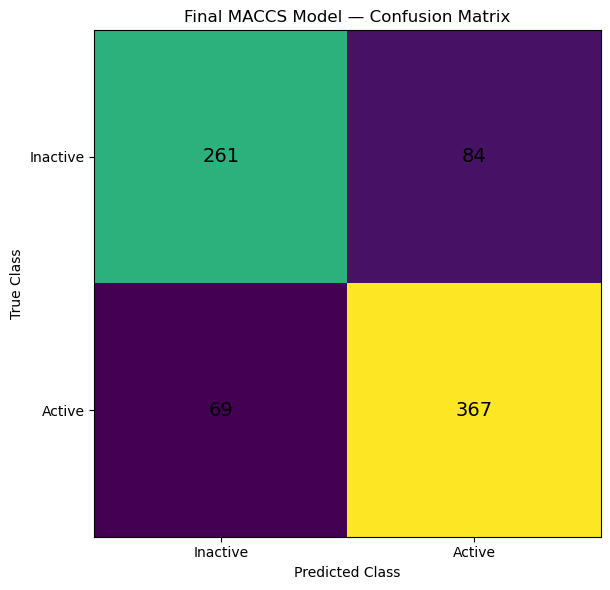


✓ Confusion matrix saved:
  grand_final_selection/final_maccs_confusion_matrix.png


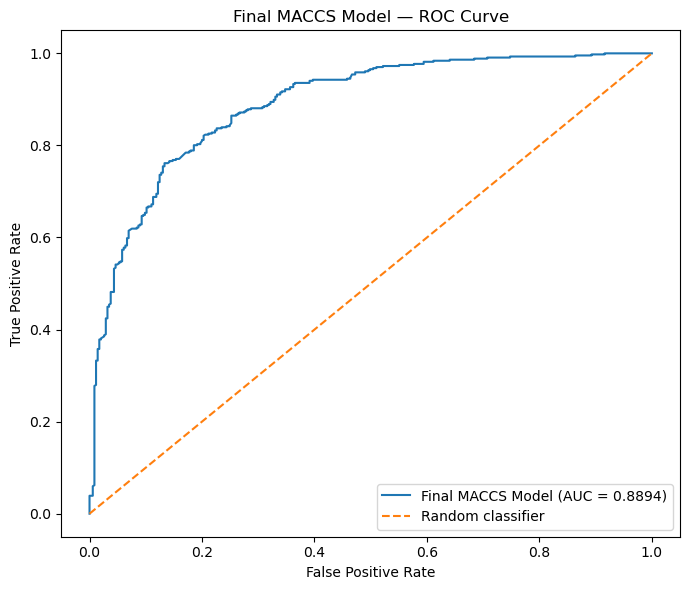


✓ ROC curve saved:
  grand_final_selection/final_maccs_roc_curve.png


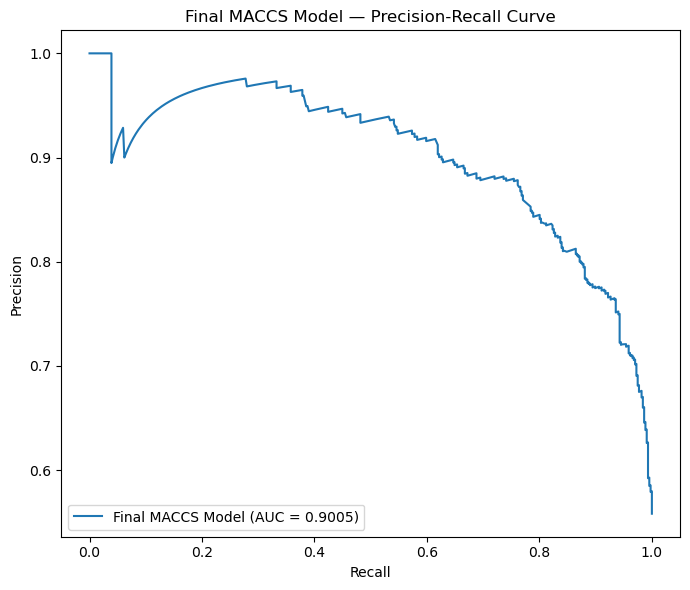


✓ Precision-Recall curve saved:
  grand_final_selection/final_maccs_precision_recall_curve.png

CELL 9 COMPLETED

Final MACCS model:
  VotingClassifier

Final test ROC-AUC:
  0.8894

Final test F1-score:
  0.8275

Final test MCC:
  0.6015

Saved files:
  ✓ grand_final_selection/final_maccs_model.joblib
  ✓ grand_final_selection/final_maccs_test_metrics.csv
  ✓ grand_final_selection/final_maccs_confusion_matrix.png
  ✓ grand_final_selection/final_maccs_roc_curve.png
  ✓ grand_final_selection/final_maccs_precision_recall_curve.png

IMPORTANT

This is the FINAL evaluation on the locked test set.

The test set must NOT be used again for:
    • Hyperparameter tuning
    • Model selection
    • Feature selection
    • Threshold optimization
    • Soft-voting selection
    • Any further model development

The MACCS model is now finalized.



In [9]:
# ============================================================================
# CELL 9 — FINAL MACCS MODEL EVALUATION ON LOCKED TEST SET
# ============================================================================
#
# IMPORTANT:
#   This is the FIRST step where X_test and y_test are used.
#
#   The final MACCS model was selected automatically from:
#       1. Best tuned individual model
#       2. Top-3 Soft Voting model
#
#   The selected model should already be saved as:
#
#       grand_final_selection/
#           final_maccs_model.joblib
#
#   This cell:
#       1. Automatically loads the final MACCS model
#       2. Evaluates it on X_test / y_test
#       3. Calculates final classification metrics
#       4. Saves the final metrics
#       5. Generates confusion matrix
#       6. Generates ROC curve
#       7. Generates Precision-Recall curve
#
#   TEST SET IS USED ONLY HERE FOR FINAL EVALUATION.
# ============================================================================


# ============================================================================
# 1. IMPORT LIBRARIES
# ============================================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    roc_curve,
    precision_recall_curve,
    auc
)


# ============================================================================
# 2. SETTINGS
# ============================================================================

FINAL_FOLDER = "grand_final_selection"

FINAL_MODEL_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_model.joblib"
)

METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_test_metrics.csv"
)

CONFUSION_MATRIX_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_confusion_matrix.png"
)

ROC_CURVE_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_roc_curve.png"
)

PR_CURVE_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_precision_recall_curve.png"
)


# ============================================================================
# 3. CHECK FINAL MODEL
# ============================================================================

print("\n" + "=" * 100)
print("FINAL MACCS MODEL — TEST SET EVALUATION")
print("=" * 100)

print("\nFinal model folder:")
print(os.path.abspath(FINAL_FOLDER))

print("\nFinal model file:")
print(FINAL_MODEL_FILE)


if not os.path.exists(FINAL_MODEL_FILE):

    raise FileNotFoundError(
        f"\nFINAL MACCS MODEL NOT FOUND:\n"
        f"{FINAL_MODEL_FILE}\n\n"
        f"Please run the previous final model selection cell first."
    )


# ============================================================================
# 4. LOAD FINAL MACCS MODEL
# ============================================================================

final_maccs_model = joblib.load(FINAL_MODEL_FILE)

print("\n✓ Final MACCS model loaded successfully.")

print("\nModel type:")
print(type(final_maccs_model).__name__)


# ============================================================================
# 5. VERIFY TEST SET
# ============================================================================

print("\n" + "=" * 100)
print("LOCKED TEST SET")
print("=" * 100)

print(f"\nTest samples : {len(X_test):,}")
print(f"Test features: {X_test.shape[1]:,}")

print("\nTest class distribution:")
print(y_test.value_counts())


# ============================================================================
# 6. GENERATE TEST PREDICTIONS
# ============================================================================

print("\n" + "=" * 100)
print("GENERATING FINAL TEST PREDICTIONS")
print("=" * 100)

# Predicted class
y_pred = final_maccs_model.predict(X_test)


# ============================================================================
# 7. GENERATE PROBABILITIES / DECISION SCORES
# ============================================================================

# Most classifiers provide predict_proba.
if hasattr(final_maccs_model, "predict_proba"):

    y_prob = final_maccs_model.predict_proba(X_test)[:, 1]

    probability_method = "predict_proba"

elif hasattr(final_maccs_model, "decision_function"):

    y_score = final_maccs_model.decision_function(X_test)

    # Convert decision scores to a 0–1 scale only for models
    # that do not provide probabilities.
    y_prob = (
        (y_score - np.min(y_score)) /
        (np.max(y_score) - np.min(y_score))
        if np.max(y_score) != np.min(y_score)
        else np.zeros_like(y_score)
    )

    probability_method = "decision_function_rescaled"

else:

    raise AttributeError(
        "The final MACCS model does not provide "
        "predict_proba() or decision_function()."
    )


print("\n✓ Predictions generated.")
print(f"Probability/score method: {probability_method}")


# ============================================================================
# 8. CONFUSION MATRIX VALUES
# ============================================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()


# ============================================================================
# 9. CALCULATE FINAL TEST METRICS
# ============================================================================

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

sensitivity = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

mcc = matthews_corrcoef(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


# ============================================================================
# 10. DISPLAY FINAL RESULTS
# ============================================================================

print("\n" + "=" * 100)
print("FINAL MACCS TEST-SET PERFORMANCE")
print("=" * 100)

print(f"\nROC-AUC              : {roc_auc:.4f}")
print(f"PR-AUC               : {pr_auc:.4f}")
print(f"Accuracy             : {accuracy:.4f}")
print(f"Balanced Accuracy    : {balanced_accuracy:.4f}")
print(f"Precision            : {precision:.4f}")
print(f"Sensitivity (Recall) : {sensitivity:.4f}")
print(f"Specificity          : {specificity:.4f}")
print(f"MCC                  : {mcc:.4f}")
print(f"F1-score             : {f1:.4f}")

print("\n" + "-" * 100)
print("CONFUSION MATRIX")
print("-" * 100)

print(f"\nTrue Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")


# ============================================================================
# 11. SAVE FINAL METRICS
# ============================================================================

final_metrics = pd.DataFrame({
    "Model": ["Final MACCS Model"],
    "Model_Type": [type(final_maccs_model).__name__],
    "ROC_AUC": [roc_auc],
    "PR_AUC": [pr_auc],
    "Accuracy": [accuracy],
    "Balanced_Accuracy": [balanced_accuracy],
    "Precision": [precision],
    "Sensitivity": [sensitivity],
    "Specificity": [specificity],
    "MCC": [mcc],
    "F1_Score": [f1],
    "TN": [tn],
    "FP": [fp],
    "FN": [fn],
    "TP": [tp],
    "Test_Samples": [len(X_test)]
})

final_metrics.to_csv(
    METRICS_FILE,
    index=False
)

print("\n✓ Final metrics saved:")
print(f"  {METRICS_FILE}")


# ============================================================================
# 12. CONFUSION MATRIX PLOT
# ============================================================================

cm = np.array([
    [tn, fp],
    [fn, tp]
])

fig, ax = plt.subplots(figsize=(7, 6))

ax.imshow(cm)

ax.set_title(
    "Final MACCS Model — Confusion Matrix"
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    CONFUSION_MATRIX_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Confusion matrix saved:")
print(f"  {CONFUSION_MATRIX_FILE}")


# ============================================================================
# 13. ROC CURVE
# ============================================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_curve_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Final MACCS Model (AUC = {roc_curve_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final MACCS Model — ROC Curve")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    ROC_CURVE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ ROC curve saved:")
print(f"  {ROC_CURVE_FILE}")


# ============================================================================
# 14. PRECISION-RECALL CURVE
# ============================================================================

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

pr_curve_auc = auc(
    recall_values,
    precision_values
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Final MACCS Model (AUC = {pr_curve_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final MACCS Model — Precision-Recall Curve")

plt.legend(loc="lower left")

plt.tight_layout()

plt.savefig(
    PR_CURVE_FILE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Precision-Recall curve saved:")
print(f"  {PR_CURVE_FILE}")


# ============================================================================
# 15. FINAL STATUS
# ============================================================================

print("\n" + "=" * 100)
print("CELL 9 COMPLETED")
print("=" * 100)

print("\nFinal MACCS model:")
print(f"  {type(final_maccs_model).__name__}")

print("\nFinal test ROC-AUC:")
print(f"  {roc_auc:.4f}")

print("\nFinal test F1-score:")
print(f"  {f1:.4f}")

print("\nFinal test MCC:")
print(f"  {mcc:.4f}")

print("\nSaved files:")
print(f"  ✓ {FINAL_MODEL_FILE}")
print(f"  ✓ {METRICS_FILE}")
print(f"  ✓ {CONFUSION_MATRIX_FILE}")
print(f"  ✓ {ROC_CURVE_FILE}")
print(f"  ✓ {PR_CURVE_FILE}")

print("\n" + "=" * 100)
print("IMPORTANT")
print("=" * 100)

print("""
This is the FINAL evaluation on the locked test set.

The test set must NOT be used again for:
    • Hyperparameter tuning
    • Model selection
    • Feature selection
    • Threshold optimization
    • Soft-voting selection
    • Any further model development

The MACCS model is now finalized.
""")

print("=" * 100)


CELL 10 — FINAL MACCS PUBLICATION ANALYSIS

Loading final MACCS model...
Final model loaded successfully:
  grand_final_selection/final_maccs_model.joblib

Model type:
  VotingClassifier

--------------------------------------------------------------------------------
DATASET INFORMATION
--------------------------------------------------------------------------------
Training samples : 3,120
Test samples     : 781
Number of features: 166

Training class distribution:
Activity
0    1379
1    1741
Name: count, dtype: int64

Test class distribution:
Activity
0    345
1    436
Name: count, dtype: int64

--------------------------------------------------------------------------------
FINAL TEST-SET PREDICTIONS
--------------------------------------------------------------------------------
Prediction completed in 0.294 seconds.

--------------------------------------------------------------------------------
FINAL TEST METRICS
---------------------------------------------------------------

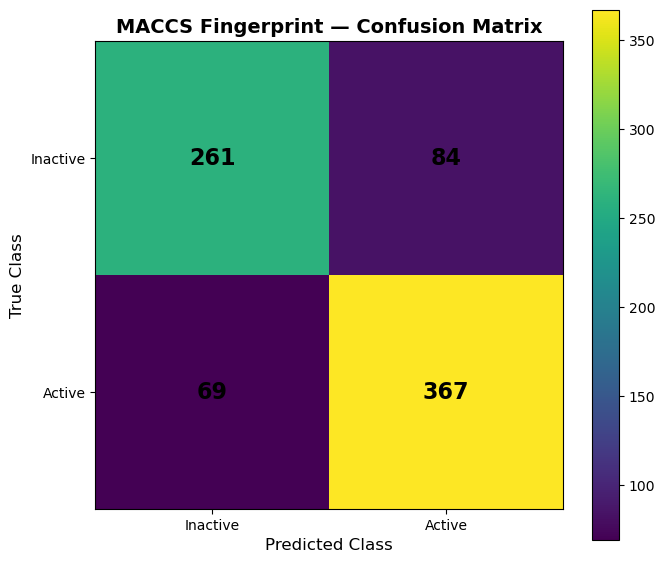

Numbered confusion matrix saved:
grand_final_selection/final_maccs_confusion_matrix_numbered.png

--------------------------------------------------------------------------------
NORMALIZED CONFUSION MATRIX
--------------------------------------------------------------------------------

Normalized confusion matrix:
          Inactive  Active
Inactive    0.7565  0.2435
Active      0.1583  0.8417


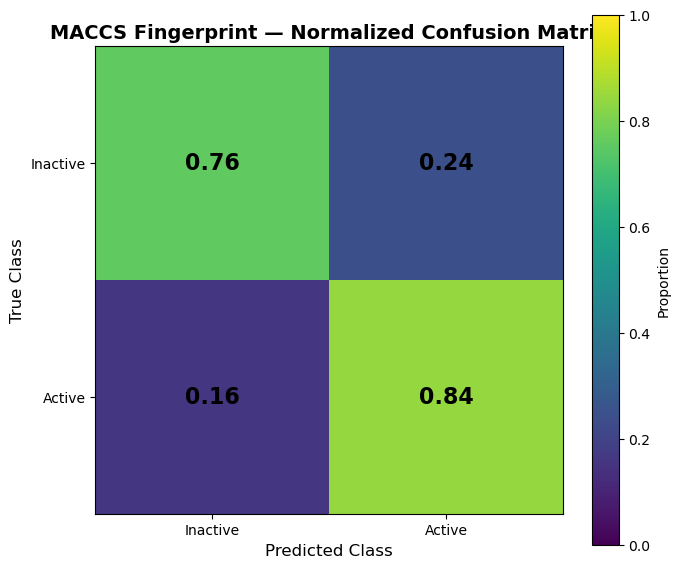

Normalized confusion matrix saved:
grand_final_selection/final_maccs_normalized_confusion_matrix.png

--------------------------------------------------------------------------------
ROC CURVE
--------------------------------------------------------------------------------


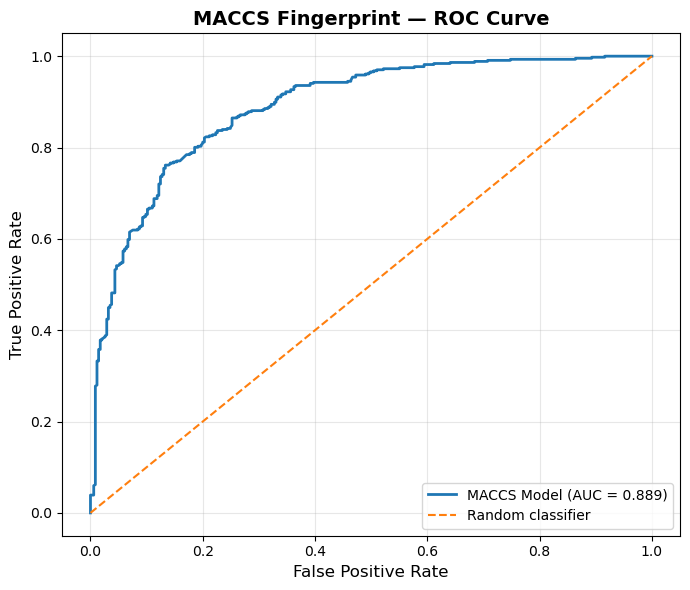

ROC curve saved:
grand_final_selection/final_maccs_roc_curve.png

--------------------------------------------------------------------------------
PRECISION–RECALL CURVE
--------------------------------------------------------------------------------


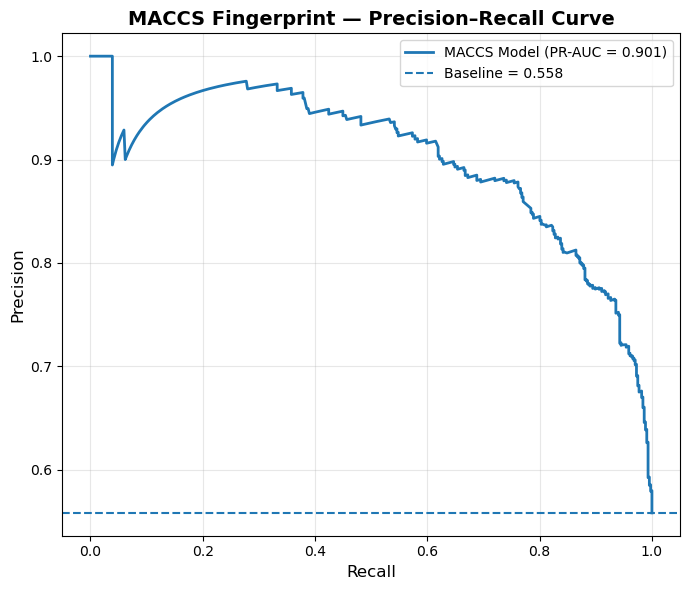

Precision–Recall curve saved:
grand_final_selection/final_maccs_precision_recall_curve.png

Y-SCRAMBLING / Y-RANDOMIZATION TEST

IMPORTANT:
  X_test and y_test are NOT used.
  Only X_train and y_train are used.
  Number of permutations: 100
  CV folds: 5

Calculating true-label CV ROC-AUC...
True-label CV ROC-AUC: 0.8785 ± 0.0107
Completed in 6.01 seconds.
Scramble   1/100 | ROC-AUC = 0.5096 | Elapsed = 6.7s
Scramble  10/100 | ROC-AUC = 0.5166 | Elapsed = 63.5s
Scramble  20/100 | ROC-AUC = 0.4976 | Elapsed = 124.6s
Scramble  30/100 | ROC-AUC = 0.5134 | Elapsed = 187.1s
Scramble  40/100 | ROC-AUC = 0.4871 | Elapsed = 250.5s
Scramble  50/100 | ROC-AUC = 0.5152 | Elapsed = 313.7s
Scramble  60/100 | ROC-AUC = 0.5162 | Elapsed = 376.3s
Scramble  70/100 | ROC-AUC = 0.5017 | Elapsed = 438.4s
Scramble  80/100 | ROC-AUC = 0.4946 | Elapsed = 501.7s
Scramble  90/100 | ROC-AUC = 0.5041 | Elapsed = 565.2s
Scramble 100/100 | ROC-AUC = 0.4946 | Elapsed = 628.8s

Y-scrambling results saved:
grand_fina

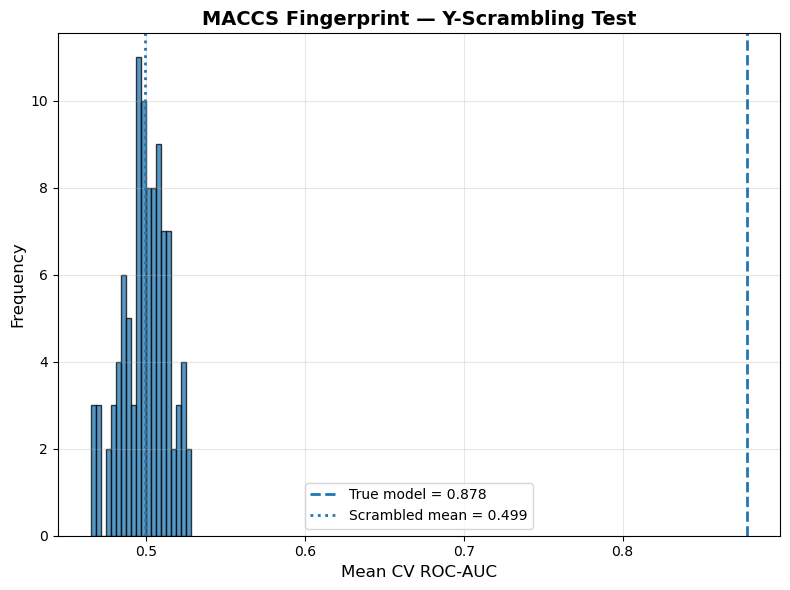

Y-scrambling figure saved:
grand_final_selection/final_maccs_y_scrambling_distribution.png

--------------------------------------------------------------------------------
PREDICTION PROBABILITY DISTRIBUTION
--------------------------------------------------------------------------------


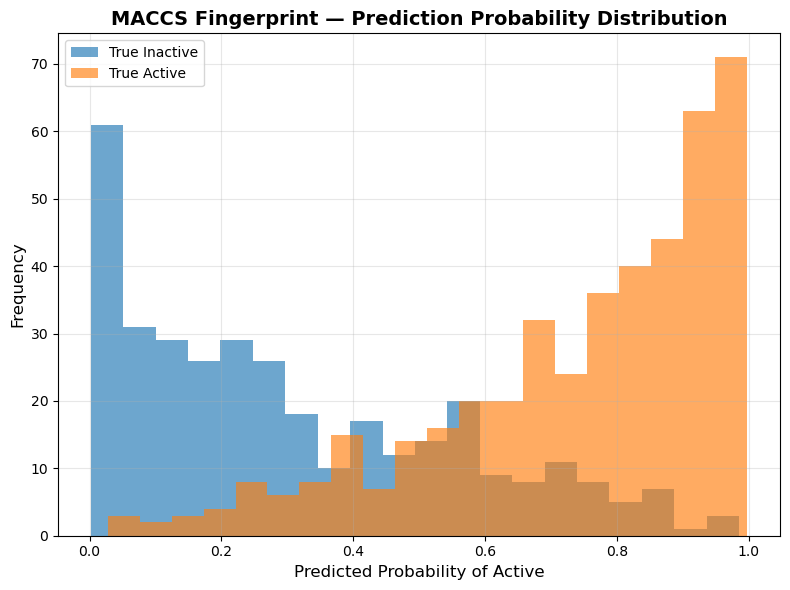

Probability distribution saved:
grand_final_selection/final_maccs_prediction_probability_distribution.png

--------------------------------------------------------------------------------
CALIBRATION CURVE
--------------------------------------------------------------------------------


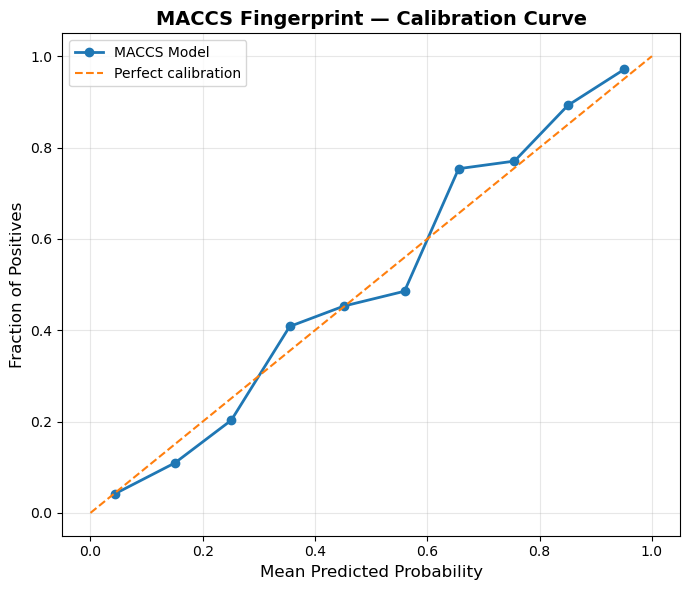

Calibration curve saved:
grand_final_selection/final_maccs_calibration_curve.png

--------------------------------------------------------------------------------
CUMULATIVE GAIN CURVE
--------------------------------------------------------------------------------


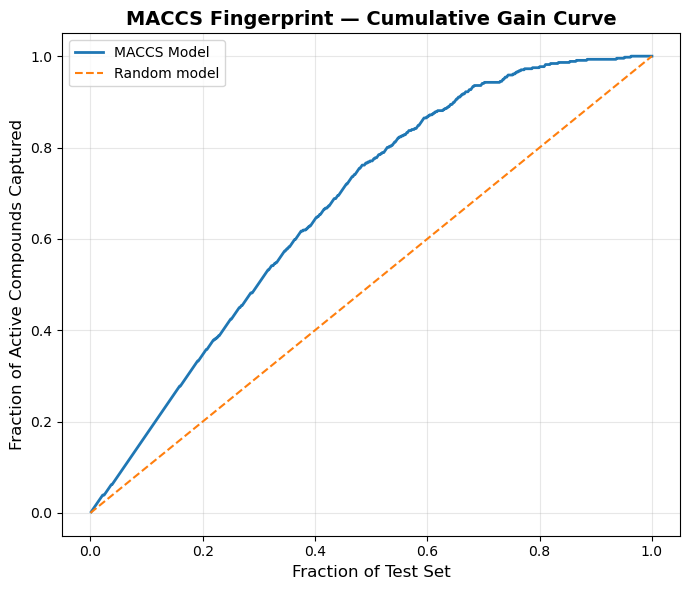

Cumulative gain curve saved:
grand_final_selection/final_maccs_cumulative_gain.png

--------------------------------------------------------------------------------
FINAL METRIC SUMMARY
--------------------------------------------------------------------------------


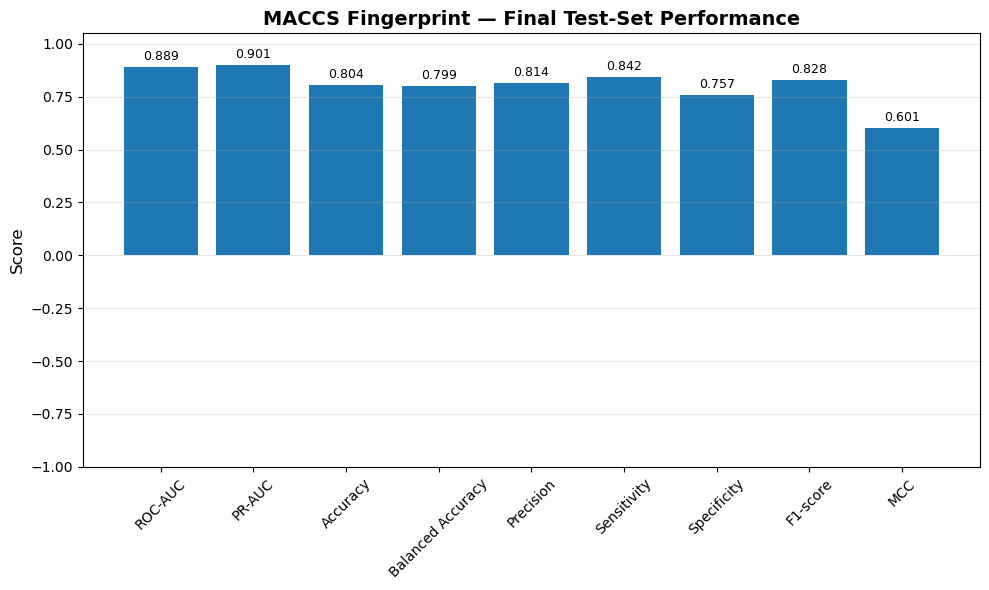

Metric summary figure saved:
grand_final_selection/final_maccs_metric_summary.png

Complete publication analysis saved:
grand_final_selection/final_maccs_complete_publication_analysis.csv
Test metrics saved:
grand_final_selection/final_maccs_test_metrics.csv

--------------------------------------------------------------------------------
CREATING MASTER PUBLICATION FIGURE
--------------------------------------------------------------------------------


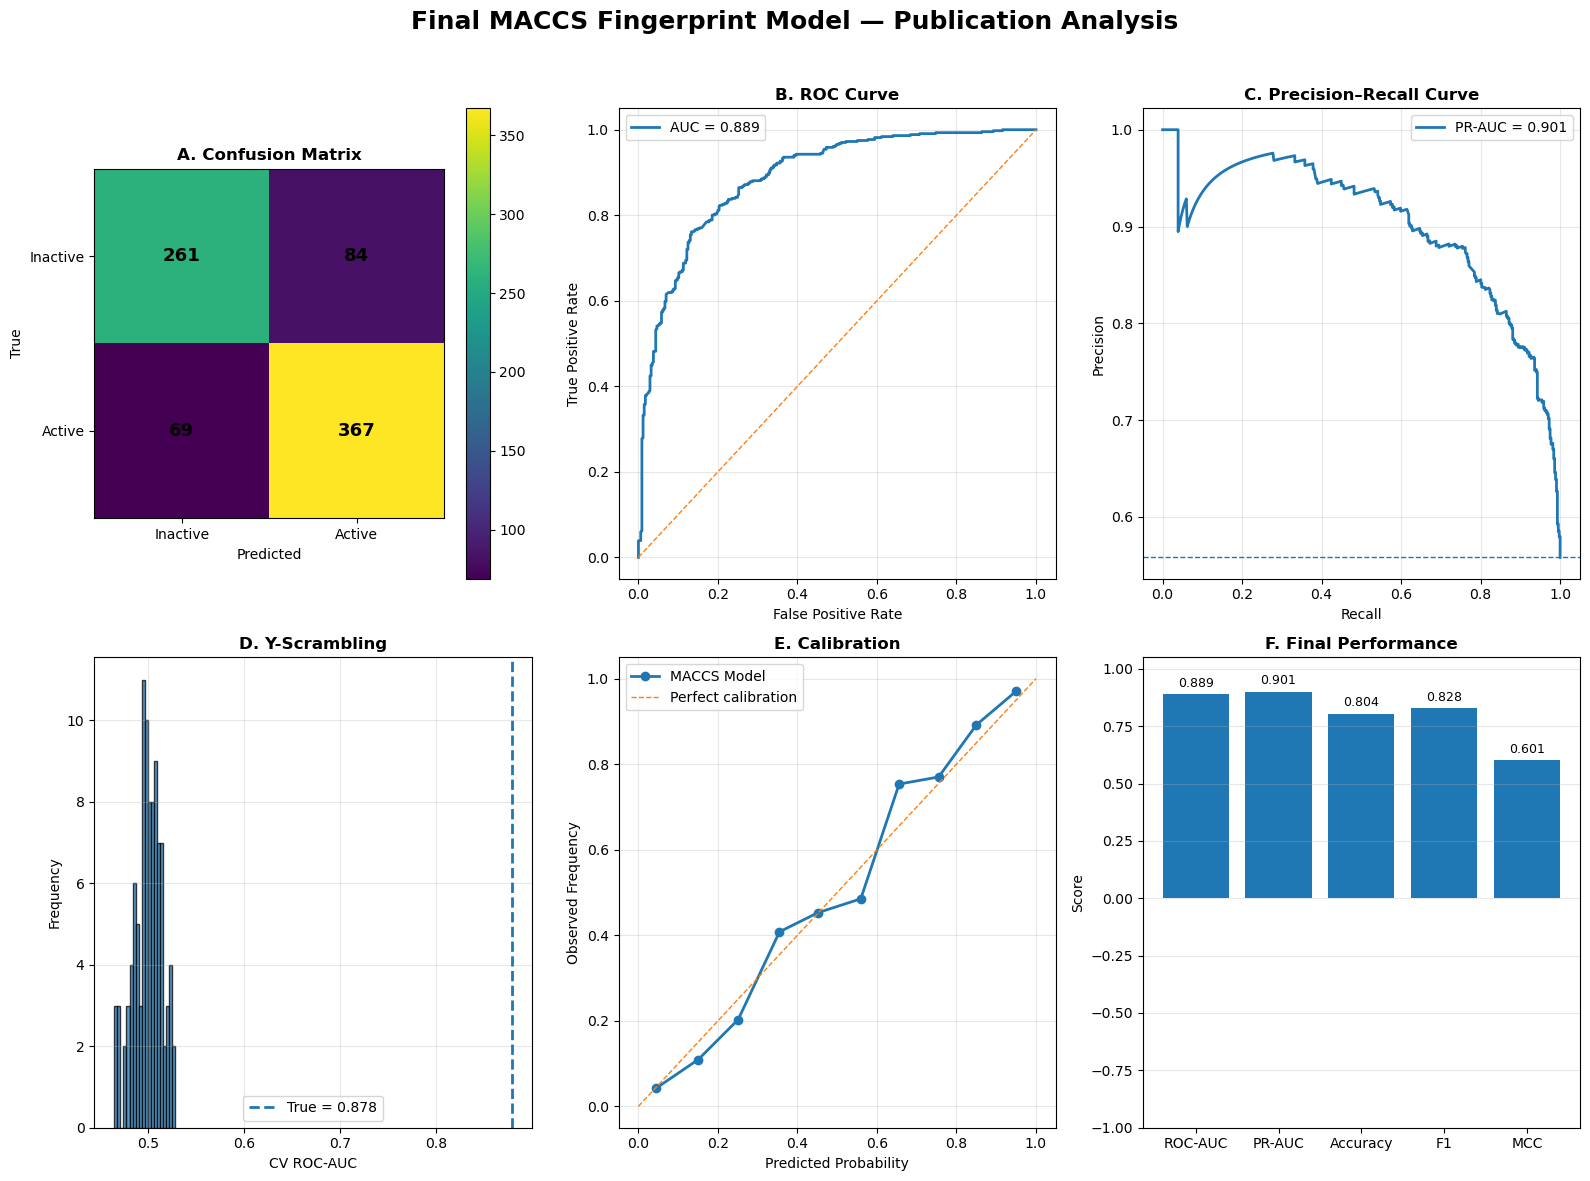

Master publication figure saved:
grand_final_selection/final_maccs_master_publication_figure.png

CELL 10 COMPLETED SUCCESSFULLY

FINAL TEST PERFORMANCE
--------------------------------------------------------------------------------
ROC-AUC               : 0.8894
PR-AUC                : 0.9007
Accuracy              : 0.8041
Balanced Accuracy     : 0.7991
Precision             : 0.8137
Sensitivity           : 0.8417
Specificity           : 0.7565
F1-score              : 0.8275
MCC                   : 0.6015
Overall Score         : 0.7963

Y-SCRAMBLING
--------------------------------------------------------------------------------
True CV ROC-AUC       : 0.8785 ± 0.0107
Scrambled mean        : 0.4992 ± 0.0145
Y-scrambling Z-score  : 26.2327
Empirical p-value     : 1.0000
Number of scrambles   : 100

FILES CREATED IN grand_final_selection/
✓ final_maccs_model.joblib                                102.61 MB
✓ final_maccs_test_metrics.csv                            0.00 MB
✓ final_maccs_p

In [10]:
# ============================================================================
# CELL 10 — FINAL MACCS MODEL: PUBLICATION-READY ANALYSIS
# ============================================================================
#
# PURPOSE
# -------
# This cell performs the final publication-oriented analysis of the already
# selected MACCS fingerprint model.
#
# IMPORTANT METHODOLOGICAL RULE
# -----------------------------
# The test set (X_test, y_test) is used ONLY for final descriptive evaluation.
# It must NOT be used for model selection or hyperparameter tuning.
#
# Y-SCRAMBLING / Y-RANDOMIZATION
# ------------------------------
# Y-scrambling is performed ONLY on the training set:
#
#       X_train + shuffled y_train
#
# The untouched test set is NEVER used during Y-scrambling.
#
# ALL OUTPUTS ARE SAVED DIRECTLY INTO:
#
#       grand_final_selection/
#
# No additional subfolders are created.
#
# ============================================================================


# ============================================================================
# 1. IMPORT LIBRARIES
# ============================================================================

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    f1_score,
    matthews_corrcoef
)

from sklearn.calibration import calibration_curve

import joblib

warnings.filterwarnings("ignore")


# ============================================================================
# 2. SETTINGS
# ============================================================================

RANDOM_STATE = 57

N_SCRAMBLES = 100

CV_FOLDS = 5

POSITIVE_CLASS = "Active"
NEGATIVE_CLASS = "Inactive"

FINAL_FOLDER = "grand_final_selection"

os.makedirs(
    FINAL_FOLDER,
    exist_ok=True
)


# ============================================================================
# 3. FILE PATHS
# ============================================================================

FINAL_MODEL_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_model.joblib"
)

TEST_METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_test_metrics.csv"
)

PUBLICATION_METRICS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_publication_metrics.csv"
)

COMPLETE_ANALYSIS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_complete_publication_analysis.csv"
)

CONFUSION_NUMBERS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_confusion_matrix_numbers.csv"
)

CONFUSION_NORMALIZED_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_normalized_confusion_matrix.csv"
)

Y_SCRAMBLING_RESULTS_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_y_scrambling_results.csv"
)

Y_SCRAMBLING_SUMMARY_FILE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_y_scrambling_summary.csv"
)


# ============================================================================
# FIGURE PATHS
# ============================================================================

CONFUSION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_confusion_matrix_numbered.png"
)

NORMALIZED_CONFUSION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_normalized_confusion_matrix.png"
)

ROC_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_roc_curve.png"
)

PR_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_precision_recall_curve.png"
)

Y_SCRAMBLING_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_y_scrambling_distribution.png"
)

PROBABILITY_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_prediction_probability_distribution.png"
)

CALIBRATION_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_calibration_curve.png"
)

GAIN_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_cumulative_gain.png"
)

METRIC_SUMMARY_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_metric_summary.png"
)

MASTER_FIGURE = os.path.join(
    FINAL_FOLDER,
    "final_maccs_master_publication_figure.png"
)


# ============================================================================
# 4. CHECK REQUIRED VARIABLES
# ============================================================================

required_variables = [
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following required variables are missing:\n"
        + ", ".join(missing_variables)
        + "\n\nPlease run the previous cells first."
    )


# ============================================================================
# 5. LOAD FINAL MODEL
# ============================================================================

print("\n" + "=" * 80)
print("CELL 10 — FINAL MACCS PUBLICATION ANALYSIS")
print("=" * 80)

print("\nLoading final MACCS model...")

if not os.path.exists(FINAL_MODEL_FILE):
    raise FileNotFoundError(
        f"Final model not found:\n{FINAL_MODEL_FILE}"
    )

final_model = joblib.load(FINAL_MODEL_FILE)

print("Final model loaded successfully:")
print(f"  {FINAL_MODEL_FILE}")

print("\nModel type:")
print(f"  {type(final_model).__name__}")


# ============================================================================
# 6. BASIC DATASET INFORMATION
# ============================================================================

print("\n" + "-" * 80)
print("DATASET INFORMATION")
print("-" * 80)

print(f"Training samples : {len(X_train):,}")
print(f"Test samples     : {len(X_test):,}")

print(f"Number of features: {X_train.shape[1]:,}")

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())


# ============================================================================
# 7. FINAL TEST-SET PREDICTIONS
# ============================================================================

print("\n" + "-" * 80)
print("FINAL TEST-SET PREDICTIONS")
print("-" * 80)

start_time = time.time()

# Class predictions
y_test_pred = final_model.predict(X_test)

# Probability predictions
if hasattr(final_model, "predict_proba"):

    y_test_proba = final_model.predict_proba(X_test)

    # Determine positive-class column
    if hasattr(final_model, "classes_"):

        classes = list(final_model.classes_)

        if 1 in classes:
            positive_index = classes.index(1)
        else:
            positive_index = 1

        y_test_probability = y_test_proba[:, positive_index]

    else:

        y_test_probability = y_test_proba[:, 1]

elif hasattr(final_model, "decision_function"):

    decision_scores = final_model.decision_function(X_test)

    # Convert decision scores to approximately 0–1 probabilities
    y_test_probability = (
        1 / (1 + np.exp(-decision_scores))
    )

else:

    raise AttributeError(
        "The final model does not provide predict_proba "
        "or decision_function."
    )

prediction_time = time.time() - start_time

print(
    f"Prediction completed in "
    f"{prediction_time:.3f} seconds."
)


# ============================================================================
# 8. CONVERT LABELS TO NUMERIC FORMAT IF NECESSARY
# ============================================================================

def convert_labels_to_binary(y):
    """
    Convert Active/Inactive or 1/0 labels into binary 1/0.
    """

    y_series = pd.Series(y)

    if y_series.dtype == object:

        mapping = {
            POSITIVE_CLASS: 1,
            NEGATIVE_CLASS: 0,
            "Active": 1,
            "Inactive": 0,
            "active": 1,
            "inactive": 0
        }

        y_binary = y_series.map(mapping)

        if y_binary.isna().any():

            unique_values = y_series.unique()

            raise ValueError(
                "Unable to convert labels to binary format.\n"
                f"Unique labels found: {unique_values}"
            )

        return y_binary.astype(int).values

    return y_series.astype(int).values


y_test_binary = convert_labels_to_binary(y_test)
y_pred_binary = convert_labels_to_binary(y_test_pred)


# ============================================================================
# 9. CALCULATE FINAL TEST METRICS
# ============================================================================

print("\n" + "-" * 80)
print("FINAL TEST METRICS")
print("-" * 80)

# ROC-AUC
test_roc_auc = roc_auc_score(
    y_test_binary,
    y_test_probability
)

# PR-AUC
test_pr_auc = average_precision_score(
    y_test_binary,
    y_test_probability
)

# Accuracy
test_accuracy = accuracy_score(
    y_test_binary,
    y_pred_binary
)

# Balanced accuracy
test_balanced_accuracy = balanced_accuracy_score(
    y_test_binary,
    y_pred_binary
)

# Precision
test_precision = precision_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# Sensitivity / Recall
test_sensitivity = recall_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# Specificity
tn, fp, fn, tp = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1]
).ravel()

if (tn + fp) > 0:
    test_specificity = tn / (tn + fp)
else:
    test_specificity = np.nan

# F1
test_f1 = f1_score(
    y_test_binary,
    y_pred_binary,
    zero_division=0
)

# MCC
test_mcc = matthews_corrcoef(
    y_test_binary,
    y_pred_binary
)

# Overall score
test_overall_score = np.mean([
    test_roc_auc,
    test_f1,
    test_mcc,
    test_accuracy,
    test_precision,
    test_sensitivity
])

test_metrics = {
    "ROC-AUC": test_roc_auc,
    "PR-AUC": test_pr_auc,
    "Accuracy": test_accuracy,
    "Balanced Accuracy": test_balanced_accuracy,
    "Precision": test_precision,
    "Sensitivity": test_sensitivity,
    "Specificity": test_specificity,
    "F1-score": test_f1,
    "MCC": test_mcc,
    "Overall Score": test_overall_score
}

for metric, value in test_metrics.items():
    print(f"{metric:20s}: {value:.4f}")


# ============================================================================
# 10. SAVE PUBLICATION METRICS
# ============================================================================

publication_metrics_df = pd.DataFrame({
    "Metric": list(test_metrics.keys()),
    "Value": list(test_metrics.values())
})

publication_metrics_df.to_csv(
    PUBLICATION_METRICS_FILE,
    index=False
)

print(
    f"\nPublication metrics saved:\n"
    f"{PUBLICATION_METRICS_FILE}"
)


# ============================================================================
# 11. CONFUSION MATRIX — NUMBERED
# ============================================================================

print("\n" + "-" * 80)
print("CONFUSION MATRIX — NUMBERED")
print("-" * 80)

cm = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=[NEGATIVE_CLASS, POSITIVE_CLASS],
    columns=[NEGATIVE_CLASS, POSITIVE_CLASS]
)

cm_df.to_csv(
    CONFUSION_NUMBERS_FILE
)

print("\nConfusion matrix:")
print(cm_df)


# ============================================================================
# 12. PLOT NUMBERED CONFUSION MATRIX
# ============================================================================

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    cm,
    interpolation="nearest"
)

ax.set_title(
    "MACCS Fingerprint — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12
)

ax.set_ylabel(
    "True Class",
    fontsize=12
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

fig.colorbar(
    im,
    ax=ax
)

plt.tight_layout()

plt.savefig(
    CONFUSION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Numbered confusion matrix saved:\n"
    f"{CONFUSION_FIGURE}"
)


# ============================================================================
# 13. NORMALIZED CONFUSION MATRIX
# ============================================================================

print("\n" + "-" * 80)
print("NORMALIZED CONFUSION MATRIX")
print("-" * 80)

cm_normalized = confusion_matrix(
    y_test_binary,
    y_pred_binary,
    labels=[0, 1],
    normalize="true"
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=[NEGATIVE_CLASS, POSITIVE_CLASS],
    columns=[NEGATIVE_CLASS, POSITIVE_CLASS]
)

cm_normalized_df.to_csv(
    CONFUSION_NORMALIZED_FILE
)

print("\nNormalized confusion matrix:")
print(
    cm_normalized_df.round(4)
)


# ============================================================================
# 14. PLOT NORMALIZED CONFUSION MATRIX
# ============================================================================

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    vmin=0,
    vmax=1
)

ax.set_title(
    "MACCS Fingerprint — Normalized Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12
)

ax.set_ylabel(
    "True Class",
    fontsize=12
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Proportion"
)

plt.tight_layout()

plt.savefig(
    NORMALIZED_CONFUSION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Normalized confusion matrix saved:\n"
    f"{NORMALIZED_CONFUSION_FIGURE}"
)


# ============================================================================
# 15. ROC CURVE
# ============================================================================

print("\n" + "-" * 80)
print("ROC CURVE")
print("-" * 80)

fpr, tpr, roc_thresholds = roc_curve(
    y_test_binary,
    y_test_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"MACCS Model (AUC = {test_roc_auc:.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=12
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — ROC Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend(
    loc="lower right"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ROC_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"ROC curve saved:\n"
    f"{ROC_FIGURE}"
)


# ============================================================================
# 16. PRECISION–RECALL CURVE
# ============================================================================

print("\n" + "-" * 80)
print("PRECISION–RECALL CURVE")
print("-" * 80)

precision_curve, recall_curve, pr_thresholds = precision_recall_curve(
    y_test_binary,
    y_test_probability
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"MACCS Model (PR-AUC = {test_pr_auc:.3f})"
)

baseline = np.mean(y_test_binary)

ax.axhline(
    baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline = {baseline:.3f}"
)

ax.set_xlabel(
    "Recall",
    fontsize=12
)

ax.set_ylabel(
    "Precision",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Precision–Recall Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend(
    loc="best"
)

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PR_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Precision–Recall curve saved:\n"
    f"{PR_FIGURE}"
)


# ============================================================================
# 17. Y-SCRAMBLING / Y-RANDOMIZATION TEST
# ============================================================================
#
# IMPORTANT:
#
# The final test set is NOT used here.
#
# Only:
#
#       X_train
#       y_train
#
# are used.
#
# The final model architecture and hyperparameters remain unchanged.
#
# Only the labels are randomly shuffled.
#
# ============================================================================

print("\n" + "=" * 80)
print("Y-SCRAMBLING / Y-RANDOMIZATION TEST")
print("=" * 80)

print("\nIMPORTANT:")
print("  X_test and y_test are NOT used.")
print("  Only X_train and y_train are used.")
print(f"  Number of permutations: {N_SCRAMBLES}")
print(f"  CV folds: {CV_FOLDS}")


# ============================================================================
# 18. TRUE-LABEL CROSS-VALIDATION ROC-AUC
# ============================================================================

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\nCalculating true-label CV ROC-AUC...")

start_time = time.time()

true_cv_scores = cross_val_score(
    clone(final_model),
    X_train,
    convert_labels_to_binary(y_train),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

true_cv_mean = np.mean(true_cv_scores)
true_cv_std = np.std(true_cv_scores)

print(
    f"True-label CV ROC-AUC: "
    f"{true_cv_mean:.4f} ± {true_cv_std:.4f}"
)

print(
    f"Completed in "
    f"{time.time() - start_time:.2f} seconds."
)


# ============================================================================
# 19. Y-SCRAMBLING LOOP
# ============================================================================

X_train_for_scrambling = X_train

y_train_binary = convert_labels_to_binary(
    y_train
)

scrambled_results = []

rng = np.random.RandomState(
    RANDOM_STATE
)

scrambling_start = time.time()

for i in range(1, N_SCRAMBLES + 1):

    # ------------------------------------------------------------
    # Shuffle labels
    # ------------------------------------------------------------

    y_scrambled = rng.permutation(
        y_train_binary
    )

    # ------------------------------------------------------------
    # Create fresh copy of model
    # ------------------------------------------------------------

    scrambled_model = clone(
        final_model
    )

    # ------------------------------------------------------------
    # Cross-validation on scrambled labels
    # ------------------------------------------------------------

    scrambled_scores = cross_val_score(
        scrambled_model,
        X_train_for_scrambling,
        y_scrambled,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    scrambled_mean = np.mean(
        scrambled_scores
    )

    scrambled_std = np.std(
        scrambled_scores
    )

    scrambled_results.append({
        "Scramble": i,
        "Mean_CV_ROC_AUC": scrambled_mean,
        "SD_CV_ROC_AUC": scrambled_std,
        "Difference_From_True": (
            true_cv_mean - scrambled_mean
        )
    })

    # ------------------------------------------------------------
    # Progress
    # ------------------------------------------------------------

    if (
        i == 1
        or i % 10 == 0
        or i == N_SCRAMBLES
    ):

        elapsed = time.time() - scrambling_start

        print(
            f"Scramble {i:3d}/{N_SCRAMBLES} | "
            f"ROC-AUC = {scrambled_mean:.4f} | "
            f"Elapsed = {elapsed:.1f}s"
        )


# ============================================================================
# 20. Y-SCRAMBLING RESULTS DATAFRAME
# ============================================================================

y_scrambling_df = pd.DataFrame(
    scrambled_results
)

y_scrambling_df.to_csv(
    Y_SCRAMBLING_RESULTS_FILE,
    index=False
)

print(
    f"\nY-scrambling results saved:\n"
    f"{Y_SCRAMBLING_RESULTS_FILE}"
)


# ============================================================================
# 21. Y-SCRAMBLING SUMMARY
# ============================================================================

scrambled_mean = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].mean()

scrambled_std = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].std()

scrambled_min = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].min()

scrambled_max = y_scrambling_df[
    "Mean_CV_ROC_AUC"
].max()

# Compare true model against scrambled models
number_scrambled_below_true = np.sum(
    y_scrambling_df["Mean_CV_ROC_AUC"]
    < true_cv_mean
)

empirical_p_value = (
    number_scrambled_below_true + 1
) / (
    N_SCRAMBLES + 1
)

# Z-score
if scrambled_std > 0:

    y_scrambling_z_score = (
        true_cv_mean - scrambled_mean
    ) / scrambled_std

else:

    y_scrambling_z_score = np.nan


y_scrambling_summary = pd.DataFrame({
    "Parameter": [
        "True_CV_ROC_AUC",
        "True_CV_ROC_AUC_SD",
        "Scrambled_Mean_ROC_AUC",
        "Scrambled_SD_ROC_AUC",
        "Scrambled_Min_ROC_AUC",
        "Scrambled_Max_ROC_AUC",
        "Y_Scrambling_Z_Score",
        "Empirical_P_Value",
        "Number_of_Scrambles",
        "CV_Folds"
    ],
    "Value": [
        true_cv_mean,
        true_cv_std,
        scrambled_mean,
        scrambled_std,
        scrambled_min,
        scrambled_max,
        y_scrambling_z_score,
        empirical_p_value,
        N_SCRAMBLES,
        CV_FOLDS
    ]
})

y_scrambling_summary.to_csv(
    Y_SCRAMBLING_SUMMARY_FILE,
    index=False
)

print("\nY-scrambling summary:")
print(
    y_scrambling_summary.to_string(
        index=False
    )
)


# ============================================================================
# 22. Y-SCRAMBLING DISTRIBUTION FIGURE
# ============================================================================

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(
    y_scrambling_df["Mean_CV_ROC_AUC"],
    bins=20,
    alpha=0.75,
    edgecolor="black"
)

ax.axvline(
    true_cv_mean,
    linestyle="--",
    linewidth=2,
    label=f"True model = {true_cv_mean:.3f}"
)

ax.axvline(
    scrambled_mean,
    linestyle=":",
    linewidth=2,
    label=f"Scrambled mean = {scrambled_mean:.3f}"
)

ax.set_xlabel(
    "Mean CV ROC-AUC",
    fontsize=12
)

ax.set_ylabel(
    "Frequency",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Y-Scrambling Test",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    Y_SCRAMBLING_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Y-scrambling figure saved:\n"
    f"{Y_SCRAMBLING_FIGURE}"
)


# ============================================================================
# 23. PREDICTION PROBABILITY DISTRIBUTION
# ============================================================================

print("\n" + "-" * 80)
print("PREDICTION PROBABILITY DISTRIBUTION")
print("-" * 80)

active_probabilities = y_test_probability[
    y_test_binary == 1
]

inactive_probabilities = y_test_probability[
    y_test_binary == 0
]

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(
    inactive_probabilities,
    bins=20,
    alpha=0.65,
    label="True Inactive"
)

ax.hist(
    active_probabilities,
    bins=20,
    alpha=0.65,
    label="True Active"
)

ax.set_xlabel(
    "Predicted Probability of Active",
    fontsize=12
)

ax.set_ylabel(
    "Frequency",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Prediction Probability Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PROBABILITY_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Probability distribution saved:\n"
    f"{PROBABILITY_FIGURE}"
)


# ============================================================================
# 24. CALIBRATION CURVE
# ============================================================================

print("\n" + "-" * 80)
print("CALIBRATION CURVE")
print("-" * 80)

prob_true, prob_pred = calibration_curve(
    y_test_binary,
    y_test_probability,
    n_bins=10,
    strategy="uniform"
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="MACCS Model"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

ax.set_xlabel(
    "Mean Predicted Probability",
    fontsize=12
)

ax.set_ylabel(
    "Fraction of Positives",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Calibration Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    CALIBRATION_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Calibration curve saved:\n"
    f"{CALIBRATION_FIGURE}"
)


# ============================================================================
# 25. CUMULATIVE GAIN CURVE
# ============================================================================

print("\n" + "-" * 80)
print("CUMULATIVE GAIN CURVE")
print("-" * 80)

# Sort by predicted probability
sorted_indices = np.argsort(
    -y_test_probability
)

sorted_labels = y_test_binary[
    sorted_indices
]

total_positives = np.sum(
    y_test_binary
)

if total_positives > 0:

    cumulative_positives = np.cumsum(
        sorted_labels
    )

    cumulative_gain = (
        cumulative_positives /
        total_positives
    )

else:

    cumulative_gain = np.zeros(
        len(sorted_labels)
    )

population_fraction = (
    np.arange(1, len(sorted_labels) + 1)
    / len(sorted_labels)
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    population_fraction,
    cumulative_gain,
    linewidth=2,
    label="MACCS Model"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random model"
)

ax.set_xlabel(
    "Fraction of Test Set",
    fontsize=12
)

ax.set_ylabel(
    "Fraction of Active Compounds Captured",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Cumulative Gain Curve",
    fontsize=14,
    fontweight="bold"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    GAIN_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Cumulative gain curve saved:\n"
    f"{GAIN_FIGURE}"
)


# ============================================================================
# 26. FINAL METRIC SUMMARY FIGURE
# ============================================================================

print("\n" + "-" * 80)
print("FINAL METRIC SUMMARY")
print("-" * 80)

metric_names = [
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1-score",
    "MCC"
]

metric_values = [
    test_roc_auc,
    test_pr_auc,
    test_accuracy,
    test_balanced_accuracy,
    test_precision,
    test_sensitivity,
    test_specificity,
    test_f1,
    test_mcc
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    metric_names,
    metric_values
)

ax.set_ylim(
    min(-1, min(metric_values) - 0.05),
    1.05
)

ax.set_ylabel(
    "Score",
    fontsize=12
)

ax.set_title(
    "MACCS Fingerprint — Final Test-Set Performance",
    fontsize=14,
    fontweight="bold"
)

ax.tick_params(
    axis="x",
    rotation=45
)

for bar, value in zip(
    bars,
    metric_values
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    METRIC_SUMMARY_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Metric summary figure saved:\n"
    f"{METRIC_SUMMARY_FIGURE}"
)


# ============================================================================
# 27. COMPLETE PUBLICATION ANALYSIS TABLE
# ============================================================================

complete_analysis = {
    "Model": [
        "Final MACCS Model"
    ],
    "Fingerprint": [
        "MACCS"
    ],
    "Number_of_Keys": [
        X_train.shape[1]
    ],
    "Test_Samples": [
        len(X_test)
    ],
    "Features": [
        X_test.shape[1]
    ],
    "ROC_AUC": [
        test_roc_auc
    ],
    "PR_AUC": [
        test_pr_auc
    ],
    "Accuracy": [
        test_accuracy
    ],
    "Balanced_Accuracy": [
        test_balanced_accuracy
    ],
    "Precision": [
        test_precision
    ],
    "Sensitivity": [
        test_sensitivity
    ],
    "Specificity": [
        test_specificity
    ],
    "F1_Score": [
        test_f1
    ],
    "MCC": [
        test_mcc
    ],
    "Overall_Score": [
        test_overall_score
    ],
    "True_CV_ROC_AUC": [
        true_cv_mean
    ],
    "True_CV_ROC_AUC_SD": [
        true_cv_std
    ],
    "Y_Scrambled_Mean_ROC_AUC": [
        scrambled_mean
    ],
    "Y_Scrambled_SD": [
        scrambled_std
    ],
    "Y_Scrambling_Z_Score": [
        y_scrambling_z_score
    ],
    "Y_Scrambling_Empirical_P": [
        empirical_p_value
    ],
    "Number_of_Y_Scrambles": [
        N_SCRAMBLES
    ]
}

complete_analysis_df = pd.DataFrame(
    complete_analysis
)

complete_analysis_df.to_csv(
    COMPLETE_ANALYSIS_FILE,
    index=False
)

print(
    f"\nComplete publication analysis saved:\n"
    f"{COMPLETE_ANALYSIS_FILE}"
)


# ============================================================================
# 28. SAVE ORIGINAL TEST METRICS IF NOT ALREADY SAVED
# ============================================================================

test_metrics_df = pd.DataFrame(
    [test_metrics]
)

test_metrics_df.to_csv(
    TEST_METRICS_FILE,
    index=False
)

print(
    f"Test metrics saved:\n"
    f"{TEST_METRICS_FILE}"
)


# ============================================================================
# 29. MASTER PUBLICATION FIGURE
# ============================================================================

print("\n" + "-" * 80)
print("CREATING MASTER PUBLICATION FIGURE")
print("-" * 80)

fig = plt.figure(
    figsize=(16, 12)
)


# --------------------------------------------------------------------------
# Panel A — Confusion Matrix
# --------------------------------------------------------------------------

ax1 = fig.add_subplot(2, 3, 1)

im1 = ax1.imshow(
    cm,
    interpolation="nearest"
)

ax1.set_title(
    "A. Confusion Matrix",
    fontweight="bold"
)

ax1.set_xlabel(
    "Predicted"
)

ax1.set_ylabel(
    "True"
)

ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])

ax1.set_xticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

ax1.set_yticklabels([
    NEGATIVE_CLASS,
    POSITIVE_CLASS
])

for i in range(2):
    for j in range(2):

        ax1.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold"
        )

fig.colorbar(
    im1,
    ax=ax1
)


# --------------------------------------------------------------------------
# Panel B — ROC
# --------------------------------------------------------------------------

ax2 = fig.add_subplot(2, 3, 2)

ax2.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {test_roc_auc:.3f}"
)

ax2.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

ax2.set_title(
    "B. ROC Curve",
    fontweight="bold"
)

ax2.set_xlabel(
    "False Positive Rate"
)

ax2.set_ylabel(
    "True Positive Rate"
)

ax2.legend()

ax2.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel C — Precision–Recall
# --------------------------------------------------------------------------

ax3 = fig.add_subplot(2, 3, 3)

ax3.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"PR-AUC = {test_pr_auc:.3f}"
)

ax3.axhline(
    baseline,
    linestyle="--",
    linewidth=1
)

ax3.set_title(
    "C. Precision–Recall Curve",
    fontweight="bold"
)

ax3.set_xlabel(
    "Recall"
)

ax3.set_ylabel(
    "Precision"
)

ax3.legend()

ax3.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel D — Y-Scrambling
# --------------------------------------------------------------------------

ax4 = fig.add_subplot(2, 3, 4)

ax4.hist(
    y_scrambling_df["Mean_CV_ROC_AUC"],
    bins=20,
    alpha=0.75,
    edgecolor="black"
)

ax4.axvline(
    true_cv_mean,
    linestyle="--",
    linewidth=2,
    label=f"True = {true_cv_mean:.3f}"
)

ax4.set_title(
    "D. Y-Scrambling",
    fontweight="bold"
)

ax4.set_xlabel(
    "CV ROC-AUC"
)

ax4.set_ylabel(
    "Frequency"
)

ax4.legend()

ax4.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel E — Calibration
# --------------------------------------------------------------------------

ax5 = fig.add_subplot(2, 3, 5)

ax5.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="MACCS Model"
)

ax5.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Perfect calibration"
)

ax5.set_title(
    "E. Calibration",
    fontweight="bold"
)

ax5.set_xlabel(
    "Predicted Probability"
)

ax5.set_ylabel(
    "Observed Frequency"
)

ax5.legend()

ax5.grid(
    alpha=0.3
)


# --------------------------------------------------------------------------
# Panel F — Final Metrics
# --------------------------------------------------------------------------

ax6 = fig.add_subplot(2, 3, 6)

short_metric_names = [
    "ROC-AUC",
    "PR-AUC",
    "Accuracy",
    "F1",
    "MCC"
]

short_metric_values = [
    test_roc_auc,
    test_pr_auc,
    test_accuracy,
    test_f1,
    test_mcc
]

bars = ax6.bar(
    short_metric_names,
    short_metric_values
)

ax6.set_ylim(
    min(-1, min(short_metric_values) - 0.05),
    1.05
)

ax6.set_title(
    "F. Final Performance",
    fontweight="bold"
)

ax6.set_ylabel(
    "Score"
)

for bar, value in zip(
    bars,
    short_metric_values
):

    ax6.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax6.grid(
    axis="y",
    alpha=0.3
)


# --------------------------------------------------------------------------
# Overall master figure
# --------------------------------------------------------------------------

fig.suptitle(
    "Final MACCS Fingerprint Model — Publication Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    MASTER_FIGURE,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()

print(
    f"Master publication figure saved:\n"
    f"{MASTER_FIGURE}"
)


# ============================================================================
# 30. FINAL OUTPUT SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("CELL 10 COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nFINAL TEST PERFORMANCE")
print("-" * 80)

for metric, value in test_metrics.items():

    print(
        f"{metric:22s}: {value:.4f}"
    )


print("\nY-SCRAMBLING")
print("-" * 80)

print(
    f"True CV ROC-AUC       : "
    f"{true_cv_mean:.4f} ± {true_cv_std:.4f}"
)

print(
    f"Scrambled mean        : "
    f"{scrambled_mean:.4f} ± {scrambled_std:.4f}"
)

print(
    f"Y-scrambling Z-score  : "
    f"{y_scrambling_z_score:.4f}"
)

print(
    f"Empirical p-value     : "
    f"{empirical_p_value:.4f}"
)

print(
    f"Number of scrambles   : "
    f"{N_SCRAMBLES}"
)


# ============================================================================
# 31. LIST ALL GENERATED FILES
# ============================================================================

print("\n" + "=" * 80)
print("FILES CREATED IN grand_final_selection/")
print("=" * 80)

generated_files = [
    FINAL_MODEL_FILE,
    TEST_METRICS_FILE,
    PUBLICATION_METRICS_FILE,
    COMPLETE_ANALYSIS_FILE,
    CONFUSION_NUMBERS_FILE,
    CONFUSION_NORMALIZED_FILE,
    Y_SCRAMBLING_RESULTS_FILE,
    Y_SCRAMBLING_SUMMARY_FILE,
    CONFUSION_FIGURE,
    NORMALIZED_CONFUSION_FIGURE,
    ROC_FIGURE,
    PR_FIGURE,
    Y_SCRAMBLING_FIGURE,
    PROBABILITY_FIGURE,
    CALIBRATION_FIGURE,
    GAIN_FIGURE,
    METRIC_SUMMARY_FIGURE,
    MASTER_FIGURE
]

for file_path in generated_files:

    if os.path.exists(file_path):

        file_size_mb = (
            os.path.getsize(file_path)
            / (1024 ** 2)
        )

        print(
            f"✓ {os.path.basename(file_path):55s} "
            f"{file_size_mb:.2f} MB"
        )

    else:

        print(
            f"✗ MISSING: "
            f"{os.path.basename(file_path)}"
        )


print("\n" + "=" * 80)
print("IMPORTANT")
print("=" * 80)

print("""
1. The final test set was used only for final evaluation and figures.

2. Y-scrambling used only X_train and y_train.

3. The final model was NOT changed during this analysis.

4. All publication outputs are directly inside:
       grand_final_selection/

5. No figures/results subfolders were created.

6. The most important single figure is:
       final_maccs_master_publication_figure.png

7. Individual high-resolution figures are also available separately.

8. Y-scrambling results are stored as CSV files for statistical reporting.
""")

print("=" * 80)